<div style="background-color:blue"><h1 style="color:black;text-align:center">DATA-MINING ET MACHINE-LEARNING</h1></div>

<h1 style="color: blue; text-align: center">importation des bibliothèques</h1>

In [658]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from sklearn.preprocessing import LabelEncoder 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import itertools
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import resample  
from sklearn.metrics import (       # Importing various performance metrics from sklearn.metrics
    confusion_matrix,               # For computing confusion matrices
    classification_report,          # For generating classification reports 
    accuracy_score,                 # For calculating accuracy scores
    roc_curve, auc                 # For generating ROC curves and calculating AUC
)
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import roc_auc_score
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

<h1 style="color: blue; text-align: center">OBSERVATION DE LA BASE DE DONNEES</h1>
<h2 style="color: cyan; text-align: center">chargement du jeu de donnees</h2>

on met notre base de donnees dans la variable df pour la manipuler

In [ ]:
df=pd.read_csv("Insurance claims data.csv",sep=',')
ID=df['policy_id']

affichons les cinq premieres lignes

In [660]:
df.head().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,steering_type,turning_radius,length,width,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
0,POL045360,9.300000,1.200000,41,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.200000,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
1,POL016745,8.200000,1.800000,35,C2,27003,C1,M9,Diesel,200Nm@1750rpm,97.89bhp@3600rpm,i-DTEC,2,No,Yes,No,Yes,Yes,Drum,1498,4,Manual,Electric,4.900000,3995,1695,1051,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0
2,POL007194,9.500000,0.200000,44,C8,8794,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.200000,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
3,POL018146,5.200000,0.400000,44,C10,73430,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,Power,4.600000,3445,1515,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
4,POL049011,10.100000,1.000000,56,C13,5410,B2,M5,Diesel,200Nm@3000rpm,88.77bhp@4000rpm,1.5 Turbocharged Revotorq,2,No,Yes,No,Yes,No,Drum,1497,4,Manual,Electric,5.000000,3990,1755,1490,No,No,No,No,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0


<h2 style="color: cyan; text-align: center">dimension du jeu de donnees</h2>
le nombre de lignes et de colones du jeu de donnees est:

In [661]:
print(f"on a {df.shape[0]} lignes et {df.shape[1]} colones(features)")

on a 58592 lignes et 41 colones(features)


In [662]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  object 
 1   subscription_length               58592 non-null  float64
 2   vehicle_age                       58592 non-null  float64
 3   customer_age                      58592 non-null  int64  
 4   region_code                       58592 non-null  object 
 5   region_density                    58592 non-null  int64  
 6   segment                           58592 non-null  object 
 7   model                             58592 non-null  object 
 8   fuel_type                         58592 non-null  object 
 9   max_torque                        58592 non-null  object 
 10  max_power                         58592 non-null  object 
 11  engine_type                       58592 non-null  object 
 12  airb

On a donc 3+10=13 variables numériques pour 28 variables non-numériques

<h2 style="color: cyan; text-align: center">description des variables</h2>

<div><style>
            table{
                width: 100%;
                margin: 20px auto;
                text-align: center;
                background-color: whitesmoke;
                border-style: solid;
                border-color: rgba(74, 70, 70, 1);
            }
            tr td{
                width: 50px
                border-style: solid;
                border-color: #000;
                background-color:whitesmoke;
                color: black;
            }
            body{
                background-color: whitesmoke;
            }
    </style>
    <table style="border-collapse: collapse; text-align: center;">
            <tr>
                <td><u>VARIABLE</u><br/></td>
                <td><u>DESCRIPTION</u><br/></td>
                <td><u>TYPE</u><br/></td>
            </tr>
            <tr>
                <td><b>policy_id</b><br/></td>
                <td  style="text-align: left;">identifiant unique pour la police d'assurance<br/></td>
                <td><b>objet</b><br/></td>
            </tr>
            <tr>
                <td><b>subscription_length</b><br/></td>
                <td style="text-align: left;">La durée de validation de la police d'assurance<br/></td>
                <td><b>float</b><br/></td>
            </tr>
            <tr>
                <td><b>vehicle_age</b><br/></td>
                <td style="text-align: left;">L'âge du vehicule assuré, qui peut affecter la probabilité d'une demande d'assurance<br/></td>
                <td><b>int</b><br/></td>
            </tr>
            <tr>
                <td><b>customer_age</b><br/></td>
                <td style="text-align: left;">L'âge du client<br/></td>
                <td><b>int</b><br/></td>
            </tr>
            <tr>
                <td><b>Model</b><br/></td>
                <td style="text-align: left;">le modèle du vehicule qui peut impacter la frequence des demandes d'assurance due aux caractéristiques générales du modèle<br/></td>
                <td><b>objet</b><br/></td>
            </tr>
            <tr>
                <td><b>fuel_type</b><br/></td>
                <td style="text-align: left;">type d'essence que le vehicule utilise<br/></td>
                <td><b>objet</b><br/></td>
            </tr>
            <tr>
                <td><b>max_torque,max_power</b><br/></td>
                <td style="text-align: left;">performances du vehicule qui peuvent influencer ses conditions mécaniques<br/></td>
                <td><b>objet</b><br/></td>
            </tr>
            <tr>
                <td><b>engine_type</b><br/></td>
                <td style="text-align: left;">type d'engin<br/></td>
                <td><b>objet</b><br/></td>
            </tr>
            <tr>
                <td><b>displacement, cylinder...</b><br/></td>
                <td style="text-align: left;">spécification sur les dimensions du vehicule<br/></td>
                <td><b>float</b><br/></td>
            </tr>
            <tr>
                <td><b>region_code</b><br/></td>
                <td style="text-align: left;">la localisation géographique du client<br/></td>
                <td><b>objet</b><br/></td>
            </tr>
            <tr>
                <td><b>region_density</b><br/></td>
                <td style="text-align: left;">le nombre d'habitants dans la region du client<br/></td>
                <td><b>int</b><br/></td>
            </tr>
            <tr>
                <td><b>airbags</b><br/></td>
                <td style="text-align: left;">le nombre de airbags dans le vehicule<br/></td>
                <td><b>int</b><br/></td>
            </tr>
            <tr>
                <td><b>is_esc(Electronic stability Control),is_adjustable_streering,is_tpms(Tire Pressure Monitoring System)</b><br/></td>
                <td style="text-align: left;">varaiables qui spécifient les caractéristiques de sécurité du vehicule<br/></td>
                <td><b>bool</b><br/></td>
            </tr>
            <tr>
                <td><b>is_parking_sensors, is_parking_camera</b><br/></td>
                <td style="text-align: left;">caractéristiques d'aide pour le stationnement <br/></td>
                <td><b>bool</b><br/></td>
            </tr>
            <tr>
                <td><b>rear_brakes_type</b><br/></td>
                <td style="text-align: left;">type de freins, caractérisant la capacité d'arret du vehicule<br/></td>
                <td><b>objet</b><br/></td>
            </tr>
            <tr>
                <td><b>autres indicateurs binaires(yes/no) </b><br/></td>
                <td style="text-align: left;">pour spécifier les capacités du vehicule ainsi que ses mésures de sécurité<br/></td>
                <td><b>bool</b><br/></td>
            </tr>
            <tr>
                <td><b>claim_statut </b><br/></td>
                <td style="text-align: left;">indique si le client a déjà fait une demande d'ssistance(1) ou pas(0)<br/></td>
                <td><b>bool</b><br/></td>
            </tr>

        </table>
</div>

Nous savons donc en général ce que représente chaque variable.Pour la suite, nous allons retirer la variable policy_id qui n'a aucune utilité dans notre modèle

<h2 style="color: cyan; text-align: center">gestion des doublons,des formats et suppréssion des variables non désirées</h2>

In [663]:
#pourcentage de valeurs nulles
df.isnull().sum() * 100 / len(df)

policy_id                           0.0
subscription_length                 0.0
vehicle_age                         0.0
customer_age                        0.0
region_code                         0.0
region_density                      0.0
segment                             0.0
model                               0.0
fuel_type                           0.0
max_torque                          0.0
max_power                           0.0
engine_type                         0.0
airbags                             0.0
is_esc                              0.0
is_adjustable_steering              0.0
is_tpms                             0.0
is_parking_sensors                  0.0
is_parking_camera                   0.0
rear_brakes_type                    0.0
displacement                        0.0
cylinder                            0.0
transmission_type                   0.0
steering_type                       0.0
turning_radius                      0.0
length                              0.0


Nous n'avons donc aucune valeur manquante dans notre base de donées

In [664]:
#Nombre de doublons
df.duplicated().sum()

np.int64(0)

On n'a aucun doublon dans notre base de données

In [665]:
#supprimmons la colone inutile
df.drop(columns='policy_id', axis=1, inplace=True)

Nous avons les variables <b>max_torque</b> et <b>max_power</b> qui sont censées êtres des variables numériques mais la facon dont ils ont été remplis dans la base de donnèes, ils ont pris la classe 'objet'. Il faut donc modifier leurs classes

In [666]:
df['max_torque'] = df['max_torque'].str.extract(r'(\d+\.?\d*)').astype(float)
df['max_power'] = df['max_power'].str.extract(r'(\d+\.?\d*)').astype(float)

df.head().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})

,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,steering_type,turning_radius,length,width,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
0,9.300000,1.200000,41,C8,8794,C2,M4,Diesel,250.000000,113.450000,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.200000,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
1,8.200000,1.800000,35,C2,27003,C1,M9,Diesel,200.000000,97.890000,i-DTEC,2,No,Yes,No,Yes,Yes,Drum,1498,4,Manual,Electric,4.900000,3995,1695,1051,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0
2,9.500000,0.200000,44,C8,8794,C2,M4,Diesel,250.000000,113.450000,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.200000,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
3,5.200000,0.400000,44,C10,73430,A,M1,CNG,60.000000,40.360000,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,Power,4.600000,3445,1515,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
4,10.100000,1.000000,56,C13,5410,B2,M5,Diesel,200.000000,88.770000,1.5 Turbocharged Revotorq,2,No,Yes,No,Yes,No,Drum,1497,4,Manual,Electric,5.000000,3990,1755,1490,No,No,No,No,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0


<h2 style="color: cyan; text-align: center">gestion des valeurs aberrantes</h2>
Nous allons maintenant nous lancer dans la gestion des valeurs extremes<br>
<h3 style="color: lightblue; text-align: left">detection des valeurs aberrantes</h3>
Pour le faire, nous allons utiliser la methode IQR 

In [667]:
num_cols=df.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols=df.select_dtypes(include=['object','category']).columns.tolist()
print("nombre d'individus aux valeurs aberrantes par variable:\n")
for col in num_cols:
    Q1=df[col].quantile(0.25)#premier quartile
    Q3=df[col].quantile(0.75)#troisieme quartile
    IQR=Q3-Q1#ecart inter-quatile
    val_min=Q1-1.5*IQR#la valeur minimale des valeurs non-aberrantes
    val_max=Q3+1.5*IQR#la valeur maximale des valeurs non-aberrantes
    outliers=df[(df[col]<val_min)|(df[col]>val_max)].index#on recupere les indices des valeurs aberrantes
    print(f"{col}:{len(outliers)}<------>{100*len(outliers)/len(df):.2f}%")

nombre d'individus aux valeurs aberrantes par variable:

subscription_length:0<------>0.00%
vehicle_age:269<------>0.46%
customer_age:282<------>0.48%
region_density:3647<------>6.22%
max_torque:0<------>0.00%
max_power:0<------>0.00%
airbags:0<------>0.00%
displacement:0<------>0.00%
cylinder:0<------>0.00%
turning_radius:0<------>0.00%
length:0<------>0.00%
width:0<------>0.00%
gross_weight:0<------>0.00%
ncap_rating:0<------>0.00%
claim_status:3748<------>6.40%


On a ainsi les pourcentages de valeurs extêmes. On va devoir vérifier si ces valeurs jugées extrêmes sont des erreurs ou des valeurs à garder telles qu'elles

In [668]:
#Etudions l'age du vehicule
a_v_max=df['vehicle_age'].max()
a_v_min=df['vehicle_age'].min()
#Etudions l'age des clients
a_c_max=df['customer_age'].max()
a_c_min=df['customer_age'].min()
#Etudions les populations
p_max=df['region_density'].max()
p_min=df['region_density'].min()
print(f"\n ages des vehicules: min: {a_v_min} -------- max: {a_v_max}\n ages des clients: min: {a_c_min} -------- max: {a_c_max} \n populations:min: {p_min}--------   max: {p_max}")


 ages des vehicules: min: 0.0 -------- max: 20.0
 ages des clients: min: 35 -------- max: 75 
 populations:min: 290--------   max: 73430


* L'âge des vehicules sont entre 0(nouvelle voiture) et 20 ans: ce qui est tout à fait légitime. donc les valeurs aberrantes ne sont pas des erreurs. On les gardes
* De même,les âges des clients vont de 35 ans à 75 ans: ceci est parfaitement légitime</br>
* Pour les populations, on n'a toujours pas d'erreur car , le nombre d'habitants ici vont de 290(petites zones) à 73430(grandes zones). Ce sont des réalités rencontrées donc rien est à changer sur ce côté.


<h1 style="color: blue; text-align: center">ANALYSE EXPLORATOIRE DES DONNEES</h1>

Pour commencer on va separer les variables numeriques des variables categorielles

In [669]:
num_cols=df.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols=df.select_dtypes(include=['object','category']).columns.tolist()

Les variables numériques sont:

In [670]:
df[num_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   subscription_length  58592 non-null  float64
 1   vehicle_age          58592 non-null  float64
 2   customer_age         58592 non-null  int64  
 3   region_density       58592 non-null  int64  
 4   max_torque           58592 non-null  float64
 5   max_power            58592 non-null  float64
 6   airbags              58592 non-null  int64  
 7   displacement         58592 non-null  int64  
 8   cylinder             58592 non-null  int64  
 9   turning_radius       58592 non-null  float64
 10  length               58592 non-null  int64  
 11  width                58592 non-null  int64  
 12  gross_weight         58592 non-null  int64  
 13  ncap_rating          58592 non-null  int64  
 14  claim_status         58592 non-null  int64  
dtypes: float64(5), int64(10)
memory usag

Les variables catégorielles sont:

In [671]:
df[cat_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 25 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   region_code                       58592 non-null  object
 1   segment                           58592 non-null  object
 2   model                             58592 non-null  object
 3   fuel_type                         58592 non-null  object
 4   engine_type                       58592 non-null  object
 5   is_esc                            58592 non-null  object
 6   is_adjustable_steering            58592 non-null  object
 7   is_tpms                           58592 non-null  object
 8   is_parking_sensors                58592 non-null  object
 9   is_parking_camera                 58592 non-null  object
 10  rear_brakes_type                  58592 non-null  object
 11  transmission_type                 58592 non-null  object
 12  steering_type     

<h2 style="color: cyan; text-align: center">ANALYSE UNIVARIEE</h2>
<h3 style="color: lightblue; text-align: left">calcul des parametres</h3>
Pour chaque feature, nous allons calculer les parametres centraux et de dispersion

In [672]:
df.describe().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})


,subscription_length,vehicle_age,customer_age,region_density,max_torque,max_power,airbags,displacement,cylinder,turning_radius,length,width,gross_weight,ncap_rating,claim_status
count,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000
mean,6.111688,1.388473,44.823935,18826.858667,134.450937,78.976765,3.137066,1162.355851,3.626963,4.852893,3850.476891,1672.233667,1385.276813,1.759950,0.063968
std,4.142790,1.134413,6.935604,17660.174792,73.146794,27.699259,1.832641,266.304786,0.483616,0.228061,311.457119,112.089135,212.423085,1.389576,0.244698
min,0.000000,0.000000,35.000000,290.000000,60.000000,40.360000,1.000000,796.000000,3.000000,4.500000,3445.000000,1475.000000,1051.000000,0.000000,0.000000
25%,2.100000,0.400000,39.000000,6112.000000,60.000000,40.360000,2.000000,796.000000,3.000000,4.600000,3445.000000,1515.000000,1185.000000,0.000000,0.000000
50%,5.700000,1.200000,44.000000,8794.000000,113.000000,88.500000,2.000000,1197.000000,4.000000,4.800000,3845.000000,1735.000000,1335.000000,2.000000,0.000000
75%,10.400000,2.200000,49.000000,27003.000000,200.000000,97.890000,6.000000,1493.000000,4.000000,5.000000,3995.000000,1755.000000,1510.000000,3.000000,0.000000
max,14.000000,20.000000,75.000000,73430.000000,250.000000,118.360000,6.000000,1498.000000,4.000000,5.200000,4300.000000,1811.000000,1720.000000,5.000000,1.000000


In [673]:
df1=df.copy()#on garde la base de données orginale dans une autre variable

<h3 style="color: lightblue; text-align: left">visualisation univariee</h3>
Nous allons faire une visualisation pour chaque variable afin de comprendre la forme de la distribution

#### histogrammes

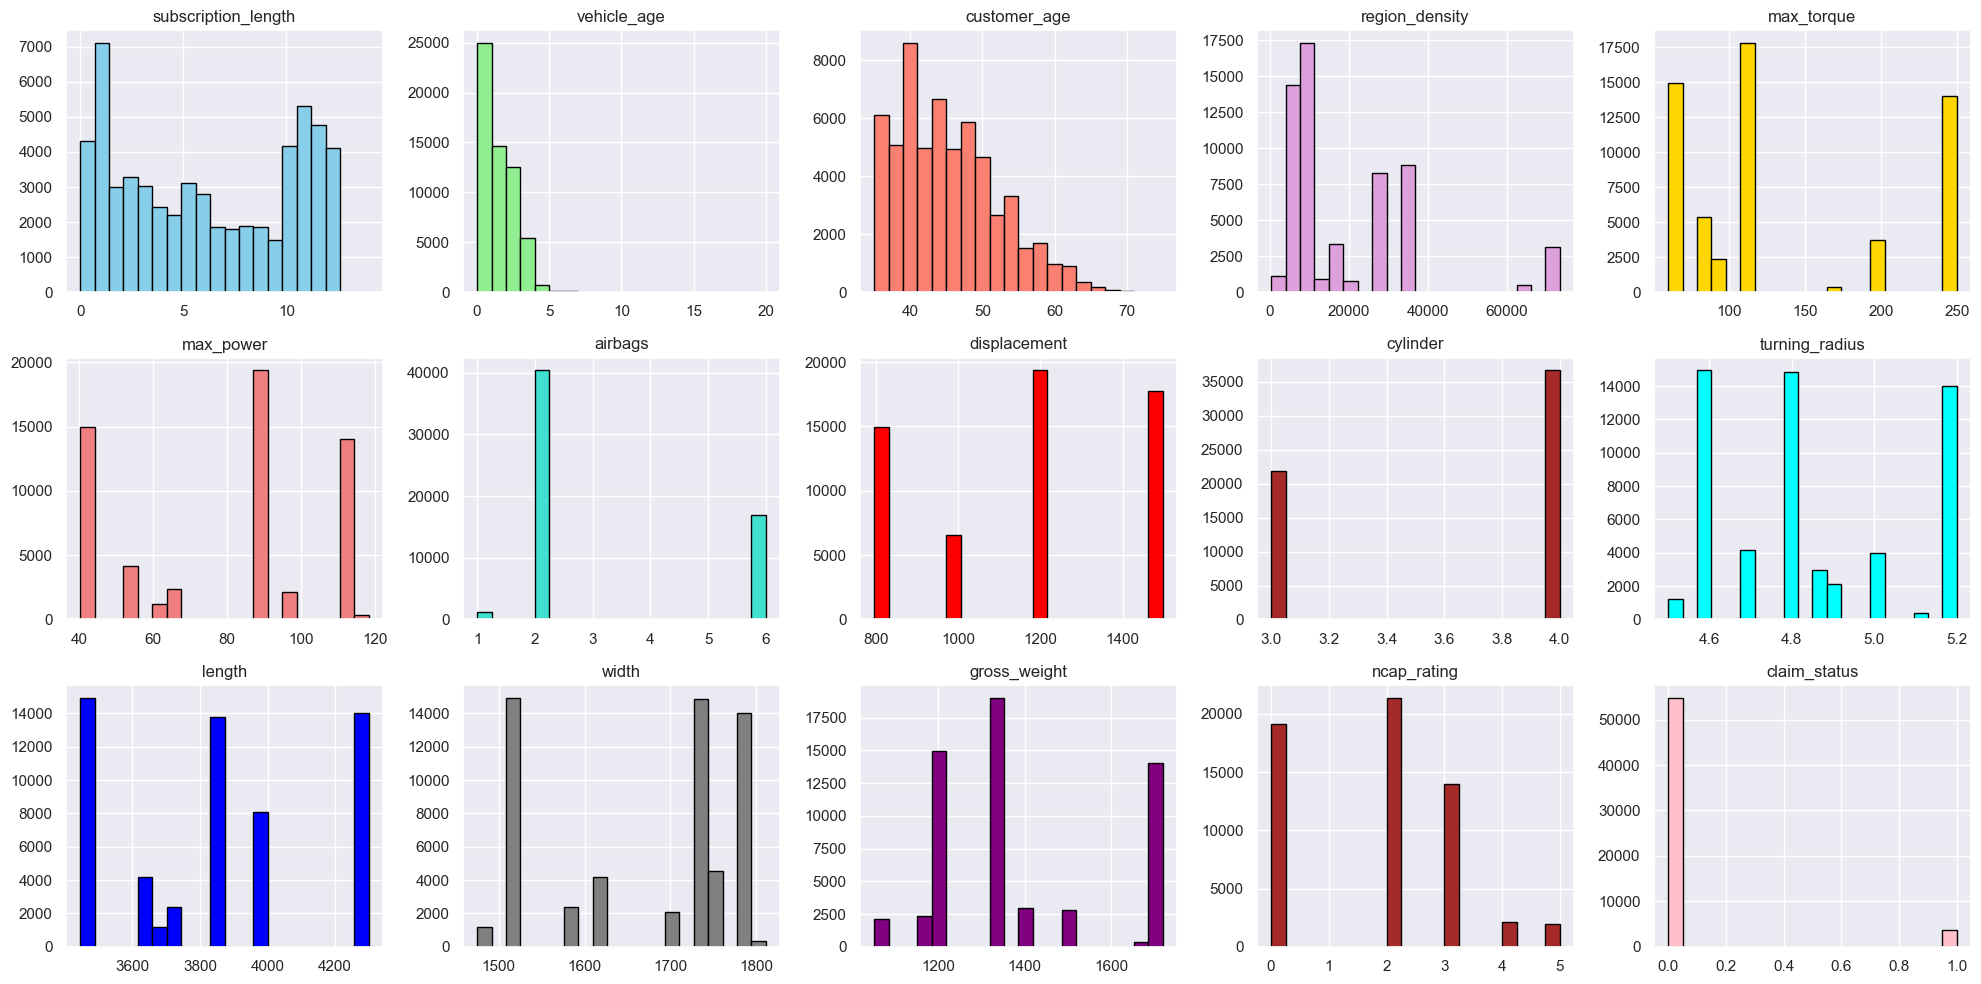

In [674]:
fig, axes = plt.subplots(3, 5, figsize=(20, 10))  # 4 lignes, 4 colonnes
axes = axes.flatten()  # aplatir pour boucle facile
colors = ['skyblue', 'lightgreen', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise','red','brown','cyan','blue','gray','purple','brown','pink']

for i, col in enumerate(num_cols):
    axes[i].hist(df[col],bins=20,color=colors[i],edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_ylabel('')
    axes[i].set_xlabel('')

# Supprimer les axes vides si nb de sous-graphes > nb de variables
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### boxplots

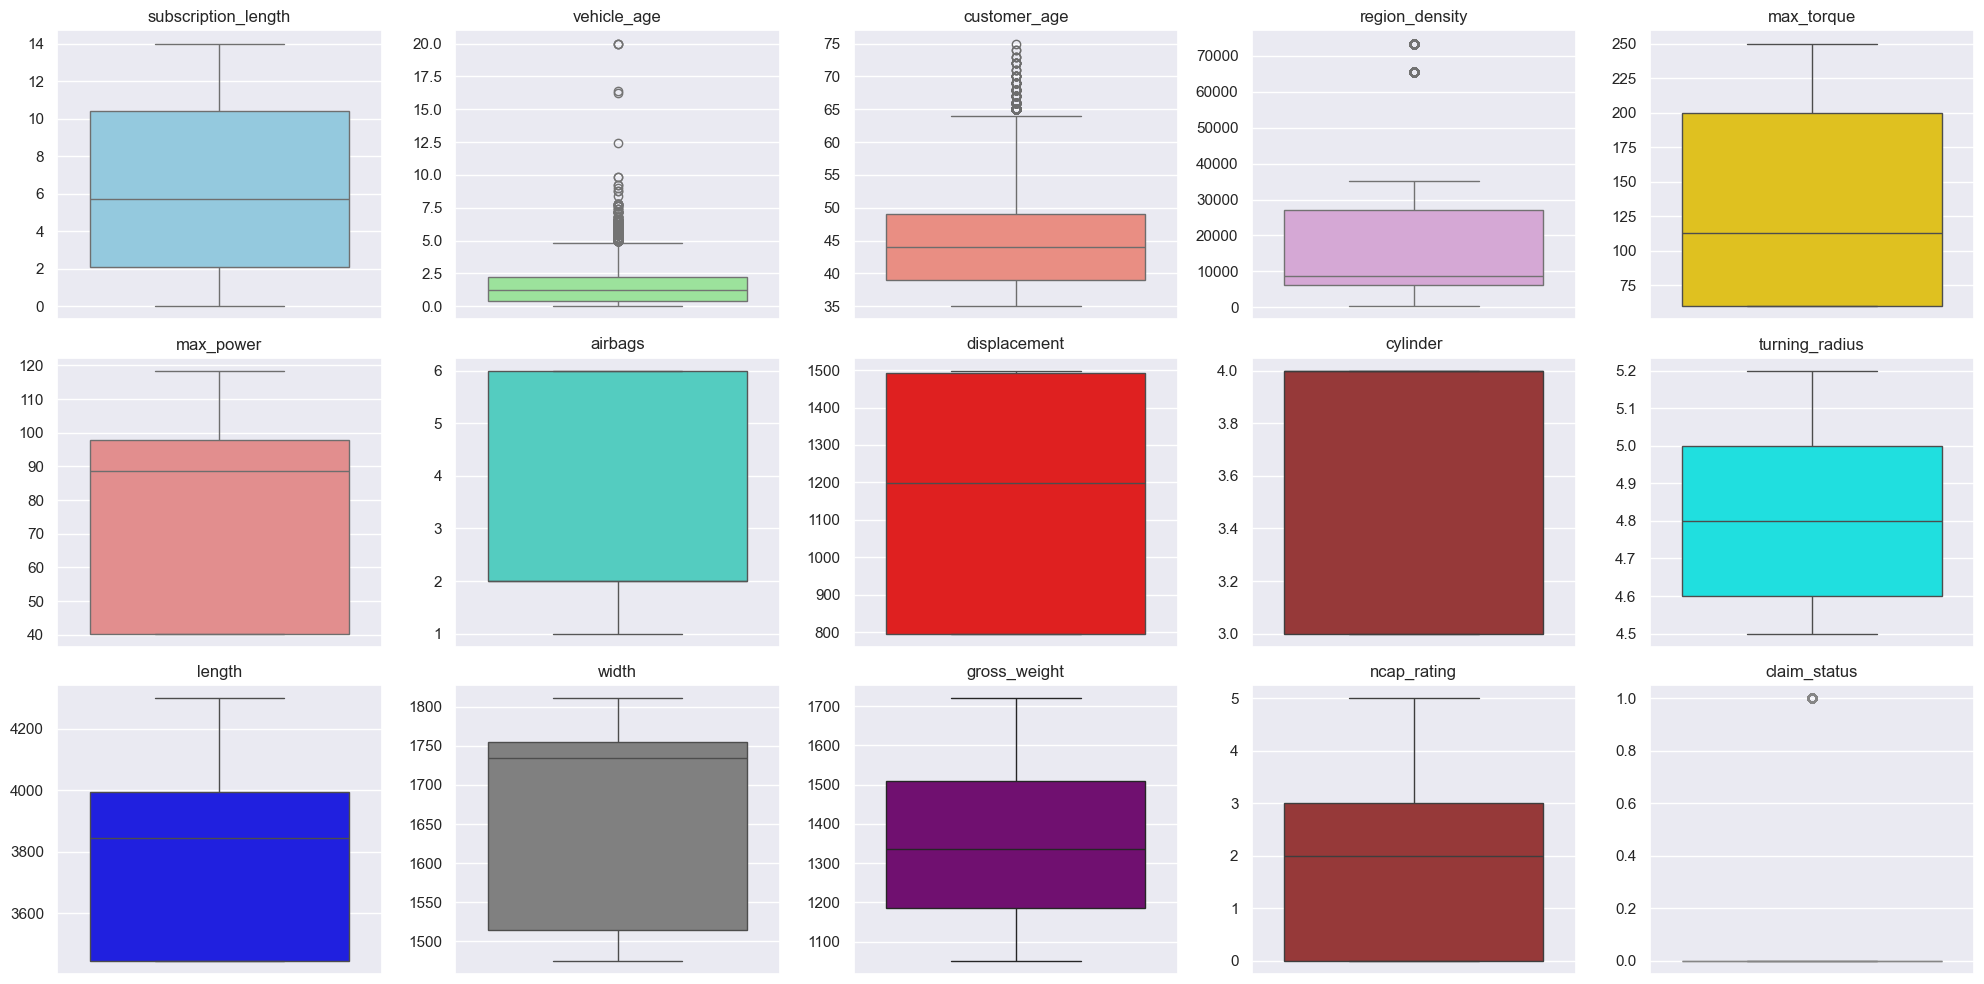

In [675]:
fig, axes = plt.subplots(3, 5, figsize=(20, 10))  # 3 lignes, 4 colonnes
axes = axes.flatten()  # aplatir pour boucle facile
colors = ['skyblue', 'lightgreen', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise','red','brown','cyan','blue','gray','purple','brown','pink']

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color=colors[i])
    axes[i].set_title(col)
    axes[i].set_ylabel('')

# Supprimer les axes vides si nb de sous-graphes > nb de variables
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### barplots

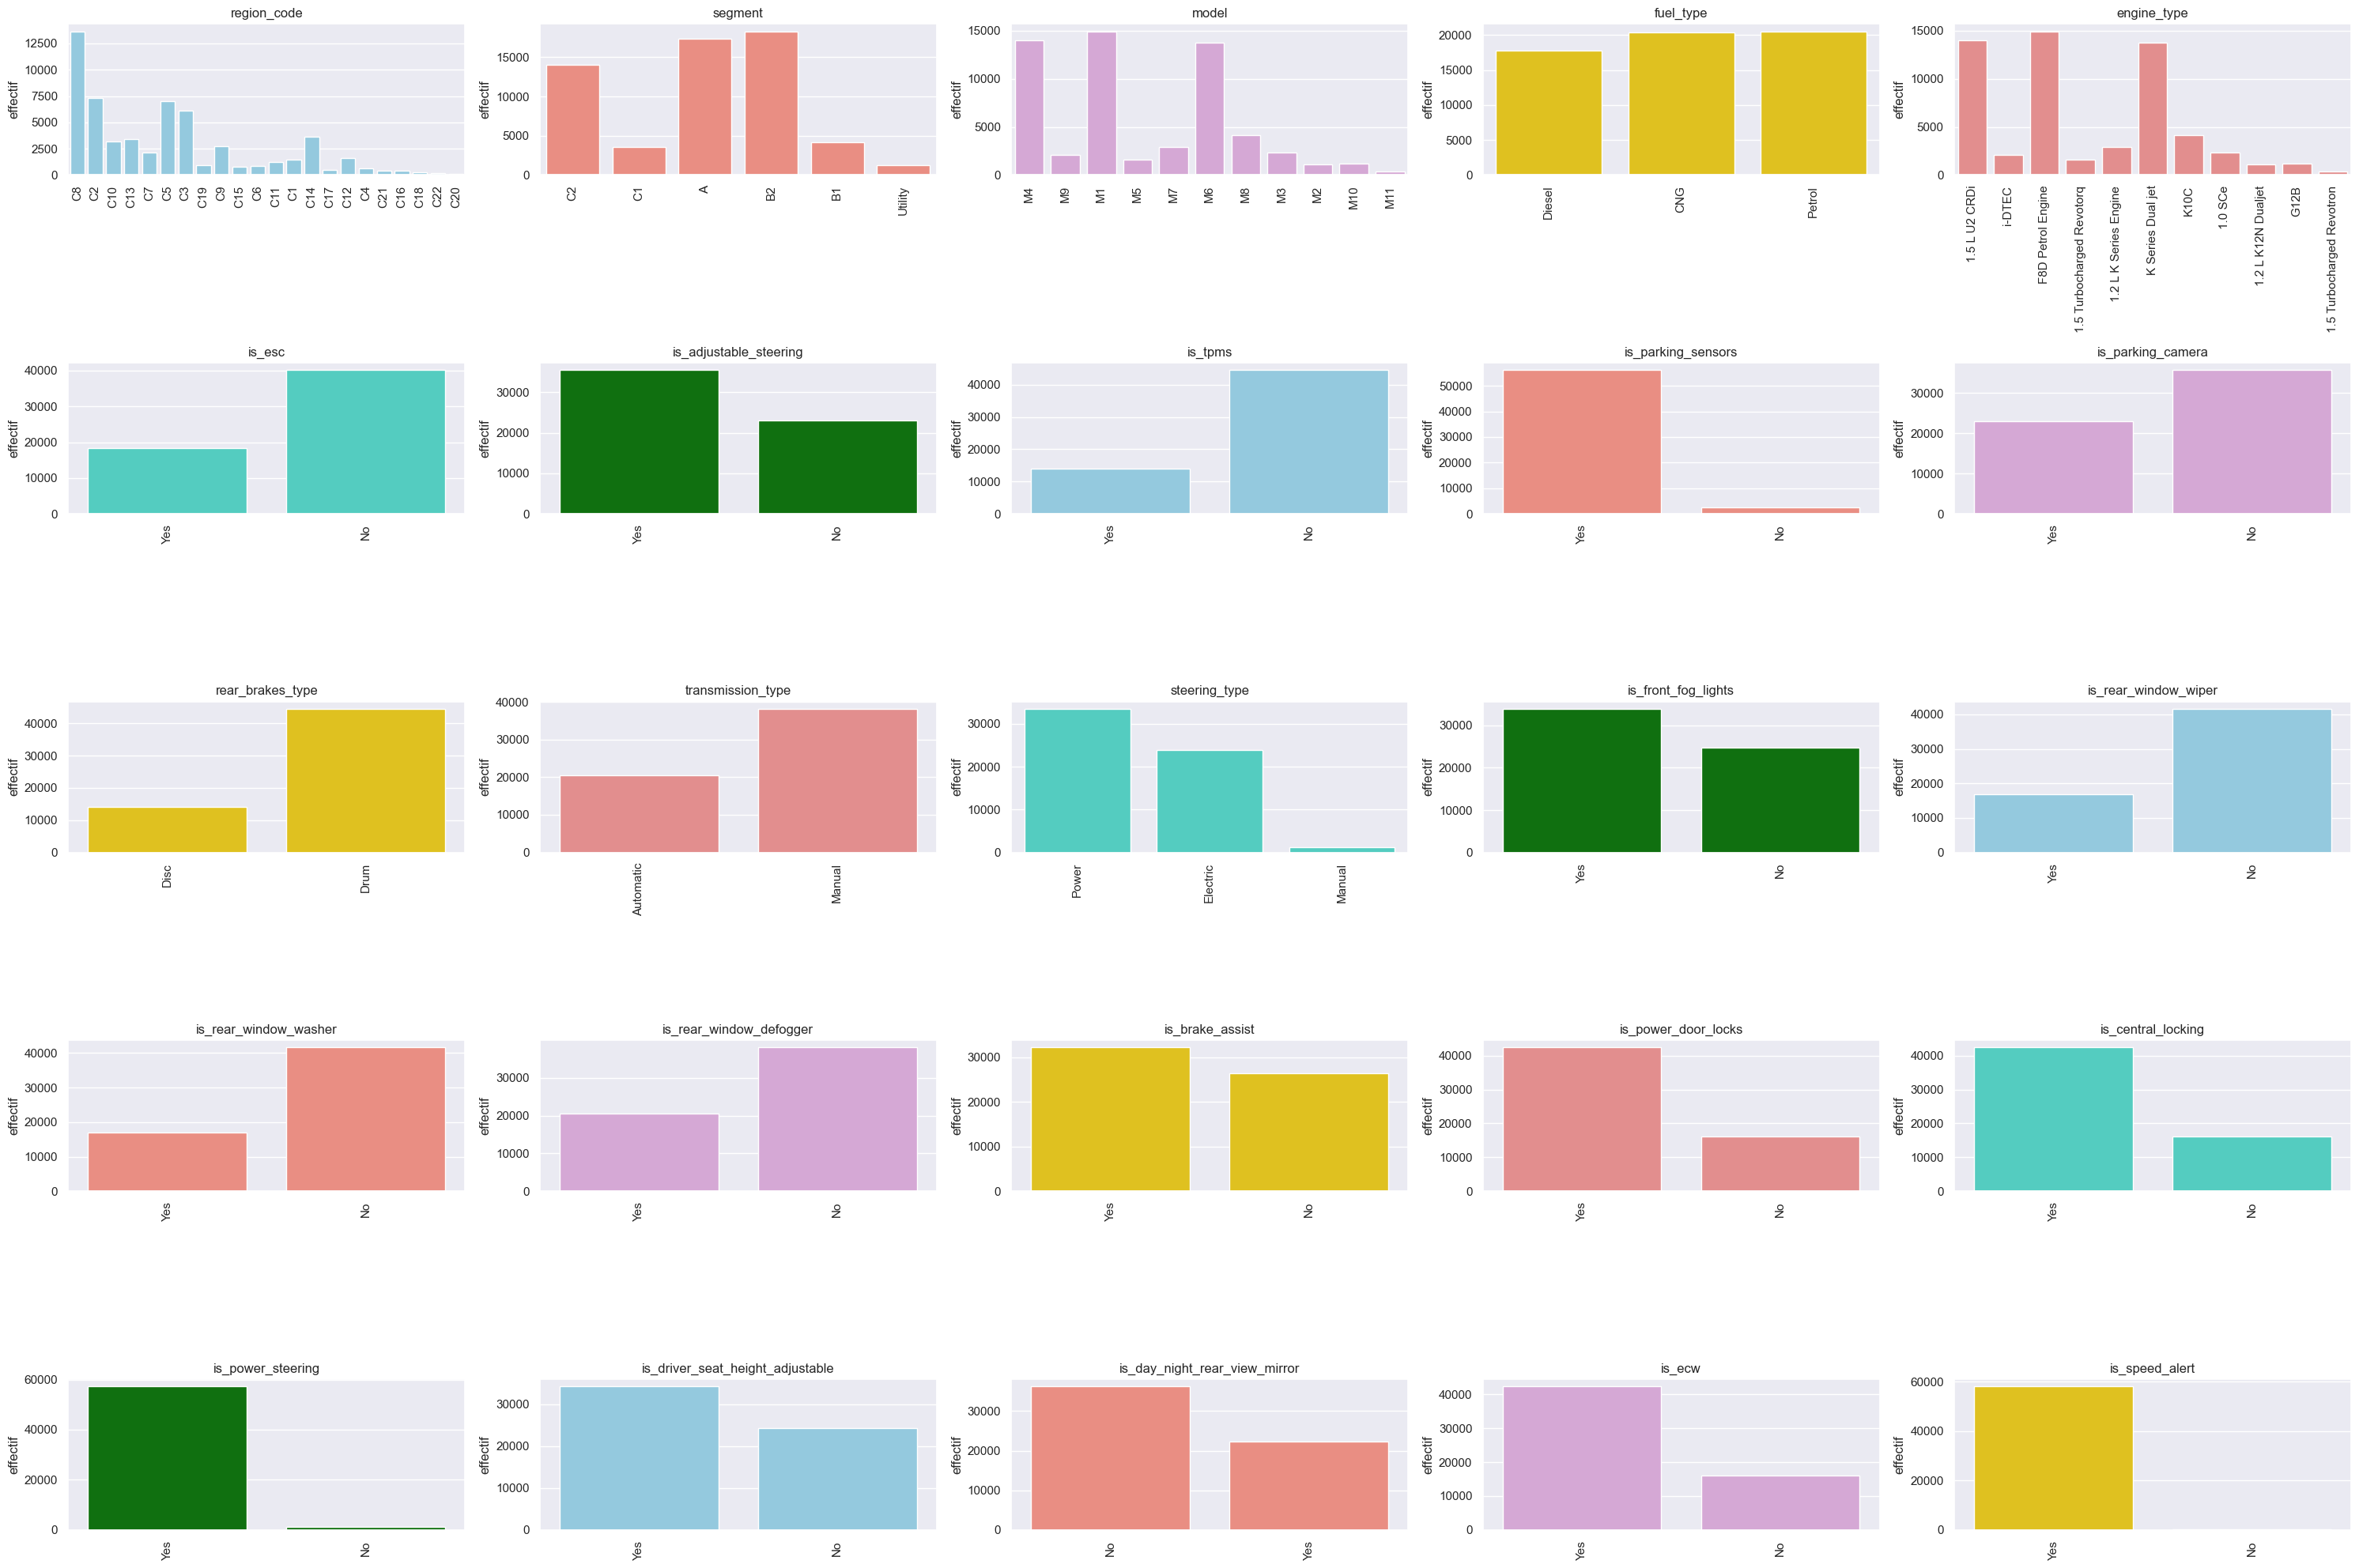

In [676]:
fig, axes = plt.subplots(5, 5, figsize=(30, 20))  # 7 lignes, 4 colonnes
axes = axes.flatten()  # aplatir pour boucle facile
colors = ['skyblue', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise','green','skyblue', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise','green','skyblue', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise','green','skyblue', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise']

for i, col in enumerate(cat_cols):
    dataframe=df
    sns.countplot(x=col,data=dataframe, ax=axes[i], color=colors[i])
    axes[i].set_title(col)
    axes[i].set_ylabel('effectif')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x',rotation=90)#on fait une rotation si les noms sont trop long

# Supprimer les axes vides si nb de sous-graphes > nb de variables
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

On retrouve graphiquement(les plus hauts pics) les differents modes qu'on a trouves plus haut

Etudions maintenant les variables et leurs comportements en fonction de notre variabe cible <b>claim_status</b>

In [677]:
# fonction pour convertir les décimaux en mois ('subscription_length', 'vehicle_age')

def singular_or_plural(count, word):
    if count == 1:
        return "1 %s" % word
    elif count > 1:
        return "%d %ss" % (count, word)

def years_and_months(float_year):
    if float_year > 0:
        year = int(float_year)
        month = int((float_year % 1) * 12)
        words = [(year, 'an'), (month, 'mois')]
        kata = ' et '.join(singular_or_plural(count, word)
                        for (count, word) in words if count > 0)
    else:kata = "moins d'un mois"
    return kata

In [678]:
df['subs_conv'] = df['subscription_length'].apply(lambda x:years_and_months(x))
df['veh_age_conv'] = df['vehicle_age'].apply(lambda x:years_and_months(x))
df['claim_status_text'] = df['claim_status'].map({1: 'yes', 0: 'no'})


sns.set()
np.random.seed(123)

On va étudier les 10 durées les plus populaires

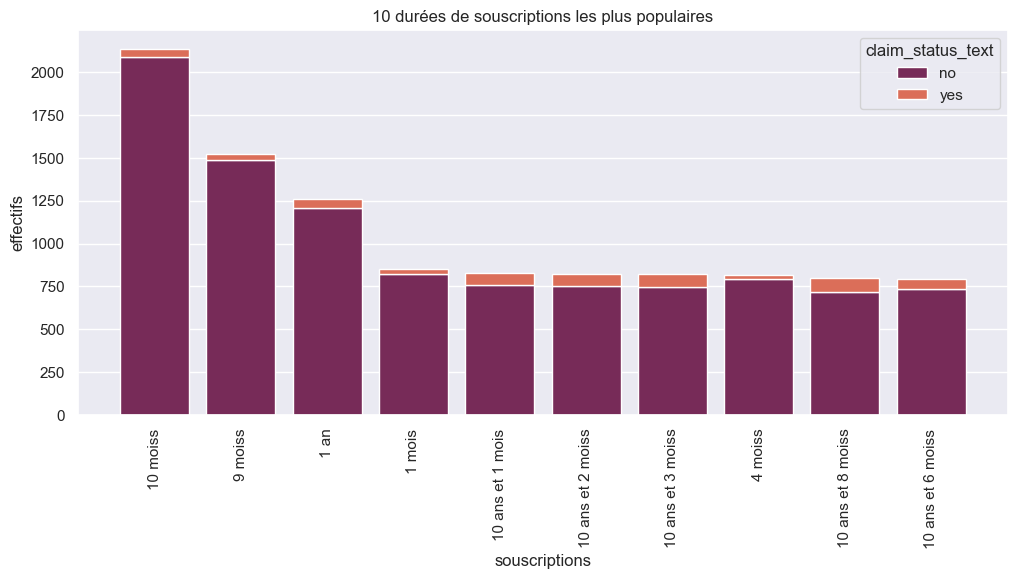

In [679]:
fig = plt.figure(figsize=(12, 5))
ax = sns.countplot(x="subs_conv", hue='claim_status_text', palette='rocket', dodge=False, data=df,
                   order=df.subs_conv.value_counts(ascending=False).iloc[:10].index,
                   hue_order=df.claim_status_text.value_counts(ascending=False).iloc[:10].index)
ax.set(xlabel="souscriptions", ylabel='effectifs', title='10 durées de souscriptions les plus populaires')
bottoms = {}
for bars in ax.containers:
    for bar in bars:
        x, y = bar.get_xy()
        h = bar.get_height()
        if x in bottoms:
            bar.set_y(bottoms[x])
            bottoms[x] += h
        else:
            bottoms[x] = h
ax.relim()  # the plot limits need to be updated with the moved bars
ax.autoscale()
plt.xticks(rotation=90)
plt.show()

Maintenant, etudions les effectifs en fonction des ages des vehicules

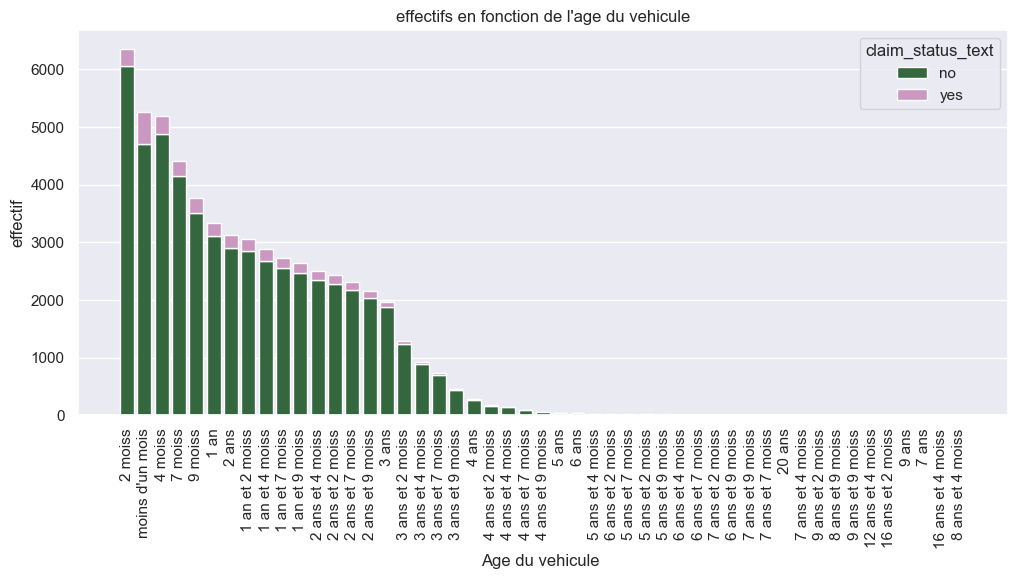

In [680]:
fig = plt.figure(figsize=(12, 5))
ax = sns.countplot(x="veh_age_conv", hue='claim_status_text', palette='cubehelix', dodge=False, data=df,
                   order=df.veh_age_conv.value_counts(ascending=False).index,
                   hue_order=df.claim_status_text.value_counts(ascending=False).index)
ax.set(xlabel="Age du vehicule ", ylabel='effectif', title="effectifs en fonction de l'age du vehicule")
bottoms = {}
for bars in ax.containers:
    for bar in bars:
        x, y = bar.get_xy()
        h = bar.get_height()
        if x in bottoms:
            bar.set_y(bottoms[x])
            bottoms[x] += h
        else:
            bottoms[x] = h
ax.relim()  # the plot limits need to be updated with the moved bars
ax.autoscale()
plt.xticks(rotation=90)
plt.show()

Maintenant, etudions les effectifs en fonction des ages des clients

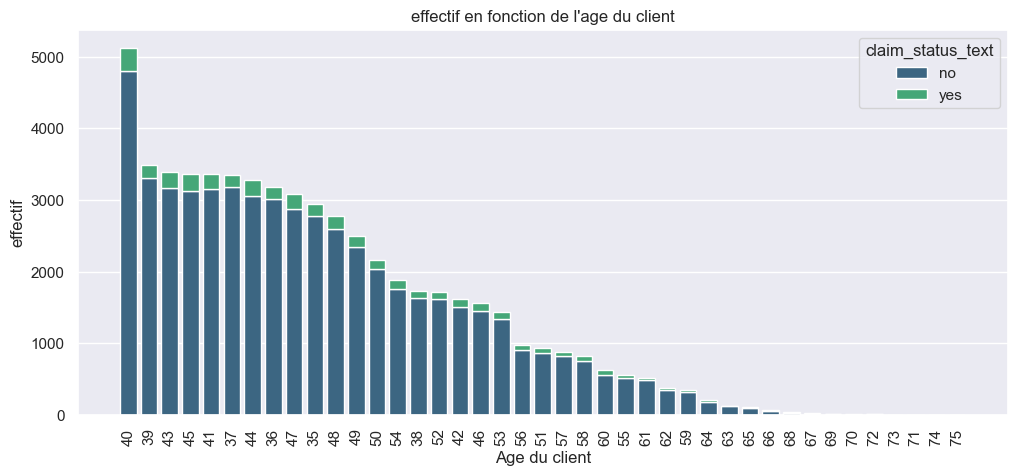

In [681]:
fig = plt.figure(figsize=(12, 5))
ax = sns.countplot(x="customer_age", hue='claim_status_text', palette='viridis', dodge=False, data=df,
                   order=df.customer_age.value_counts(ascending=False).index,
                   hue_order=df.claim_status_text.value_counts(ascending=False).index)
ax.set(xlabel="Age du client", ylabel='effectif', title="effectif en fonction de l'age du client")
bottoms = {}
for bars in ax.containers:
    for bar in bars:
        x, y = bar.get_xy()
        h = bar.get_height()
        if x in bottoms:
            bar.set_y(bottoms[x])
            bottoms[x] += h
        else:
            bottoms[x] = h
ax.relim()  # the plot limits need to be updated with the moved bars
ax.autoscale()
plt.xticks(rotation=90)
plt.show()

Maintenant, etudions les effectifs en fonction des ages des regions

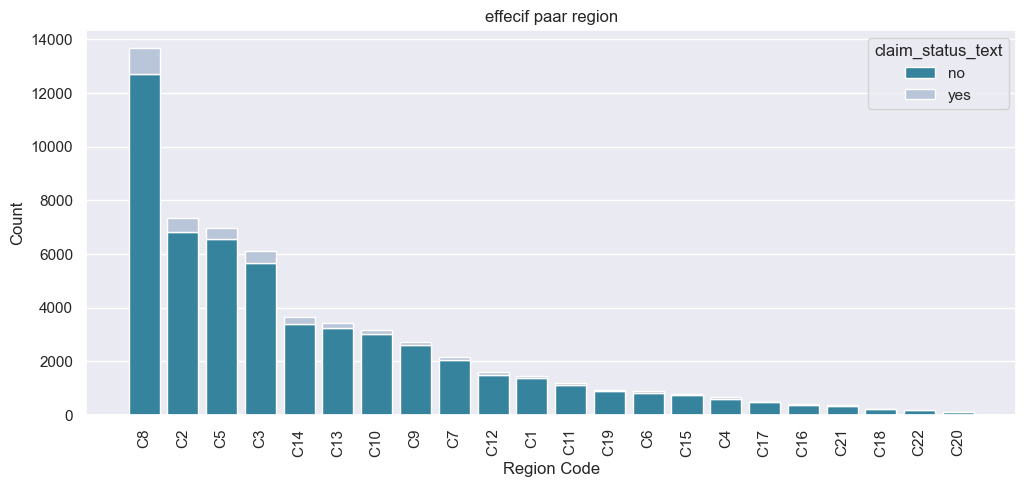

In [682]:
#sns.color_palette("vlag", as_cmap=True)

fig = plt.figure(figsize=(12, 5))
ax = sns.countplot(x="region_code", hue='claim_status_text', dodge=False, data=df, palette="PuBuGn_r",
                   order=df.region_code.value_counts(ascending=False).index,
                   hue_order=df.claim_status_text.value_counts(ascending=False).index)
ax.set(xlabel="Region Code", ylabel='Count', title='effecif paar region')
bottoms = {}
for bars in ax.containers:
    for bar in bars:
        x, y = bar.get_xy()
        h = bar.get_height()
        if x in bottoms:
            bar.set_y(bottoms[x])
            bottoms[x] += h
        else:
            bottoms[x] = h
ax.relim()  # the plot limits need to be updated with the moved bars
ax.autoscale()
plt.xticks(rotation=90)
plt.show()

Maintenant, etudions les effectifs en fonction des modèles des vehicules

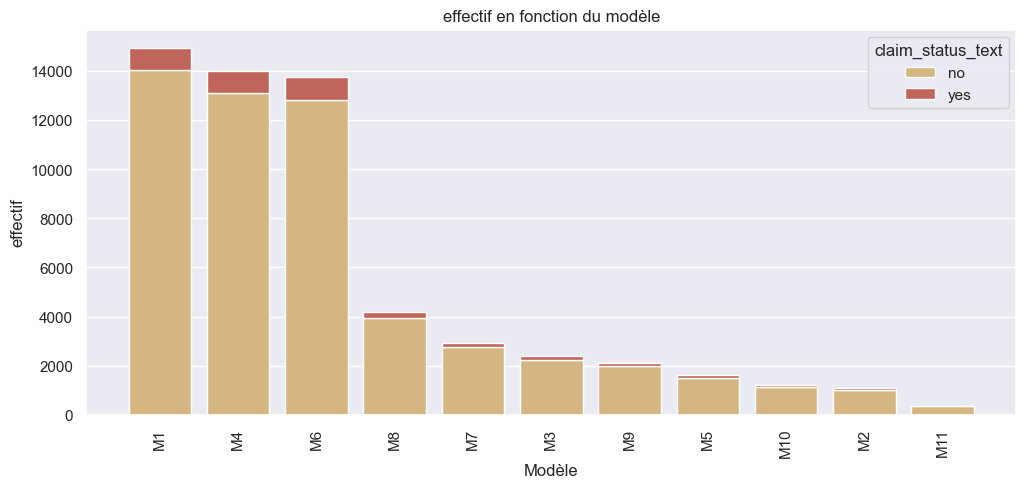

In [683]:
fig = plt.figure(figsize=(12, 5))
ax = sns.countplot(x="model", hue='claim_status_text', palette='YlOrRd', dodge=False, data=df,saturation=0.5,
                   order=df.model.value_counts(ascending=False).index,
                   hue_order=df.claim_status_text.value_counts(ascending=False).index)
ax.set(xlabel="Modèle", ylabel='effectif', title='effectif en fonction du modèle')
bottoms = {}
for bars in ax.containers:
    for bar in bars:
        x, y = bar.get_xy()
        h = bar.get_height()
        if x in bottoms:
            bar.set_y(bottoms[x])
            bottoms[x] += h
        else:
            bottoms[x] = h
ax.relim()
ax.autoscale()
plt.xticks(rotation=90)
plt.show()

In [684]:
# on supprime les colonnes inutilisées
df.drop(columns=['subs_conv', 'veh_age_conv', 'claim_status_text'], axis=1, inplace=True)

<h2 style="color: cyan; text-align: center">ANALYSE BIVARIÉE</h2>

### Numérique $\longleftrightarrow$ Numérique

Déterminons la matrice de corrélation entre les variables numériques de notre base de données

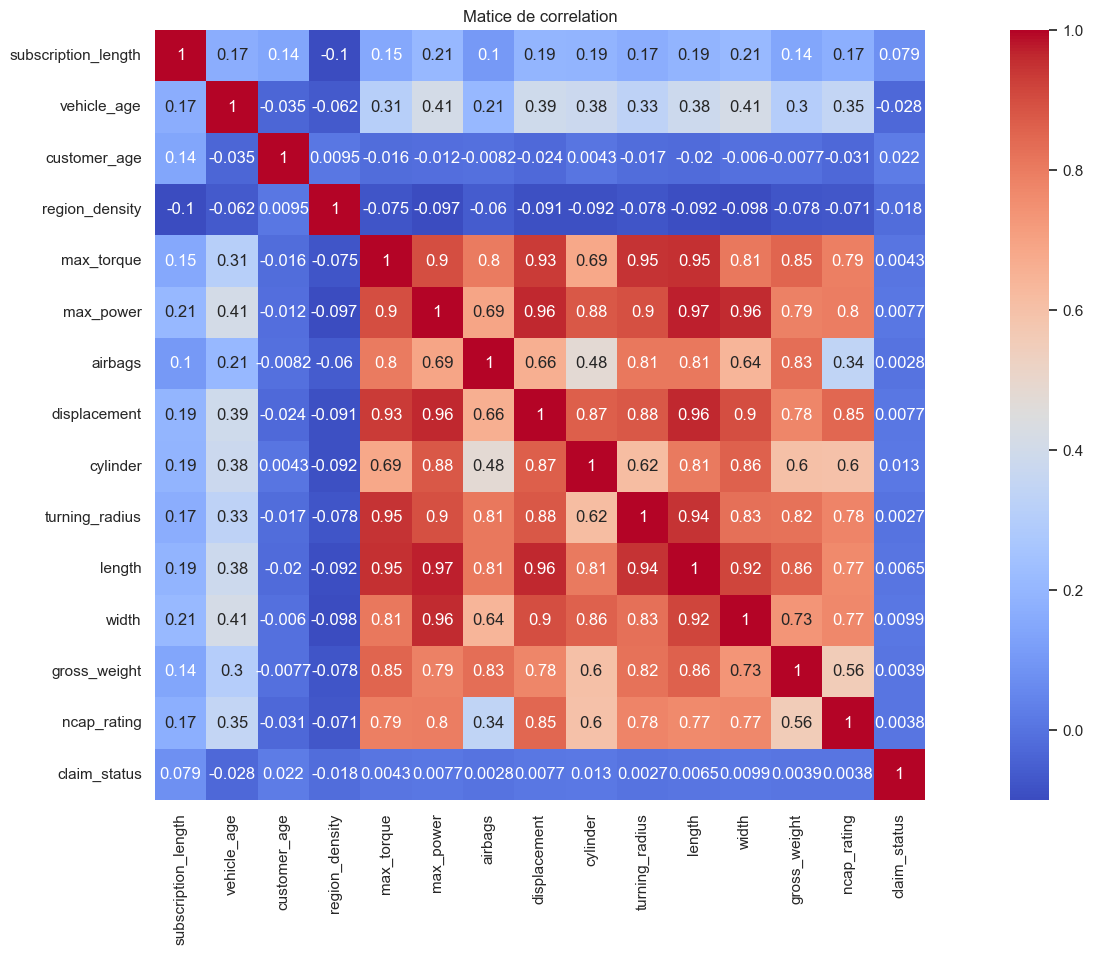

In [685]:
plt.figure(figsize=(22,10))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm',square=True)
plt.title("Matice de correlation")
plt.show()

* On constate qu'on n'a pas vraiment de forte corrélation négative, mais beaucoup de forte corrélation positive entre nos variables numérique, particulièrement entre les variables : <b>'airbags', 'displacement', 'cylinder', 'turning_radius', 'length', 'width', 'gross_weight', 'ncap_rating','max_power','max_torque'</b>
* On se rends aussi compte que notre variable cible est très faiblement correlée avec les autres

### catégorielle $\longleftrightarrow$ catégorielle

Pour cette analyse, on va determiner la force de relation entre les variables catégorielle grace à la matrice de v de Cramer

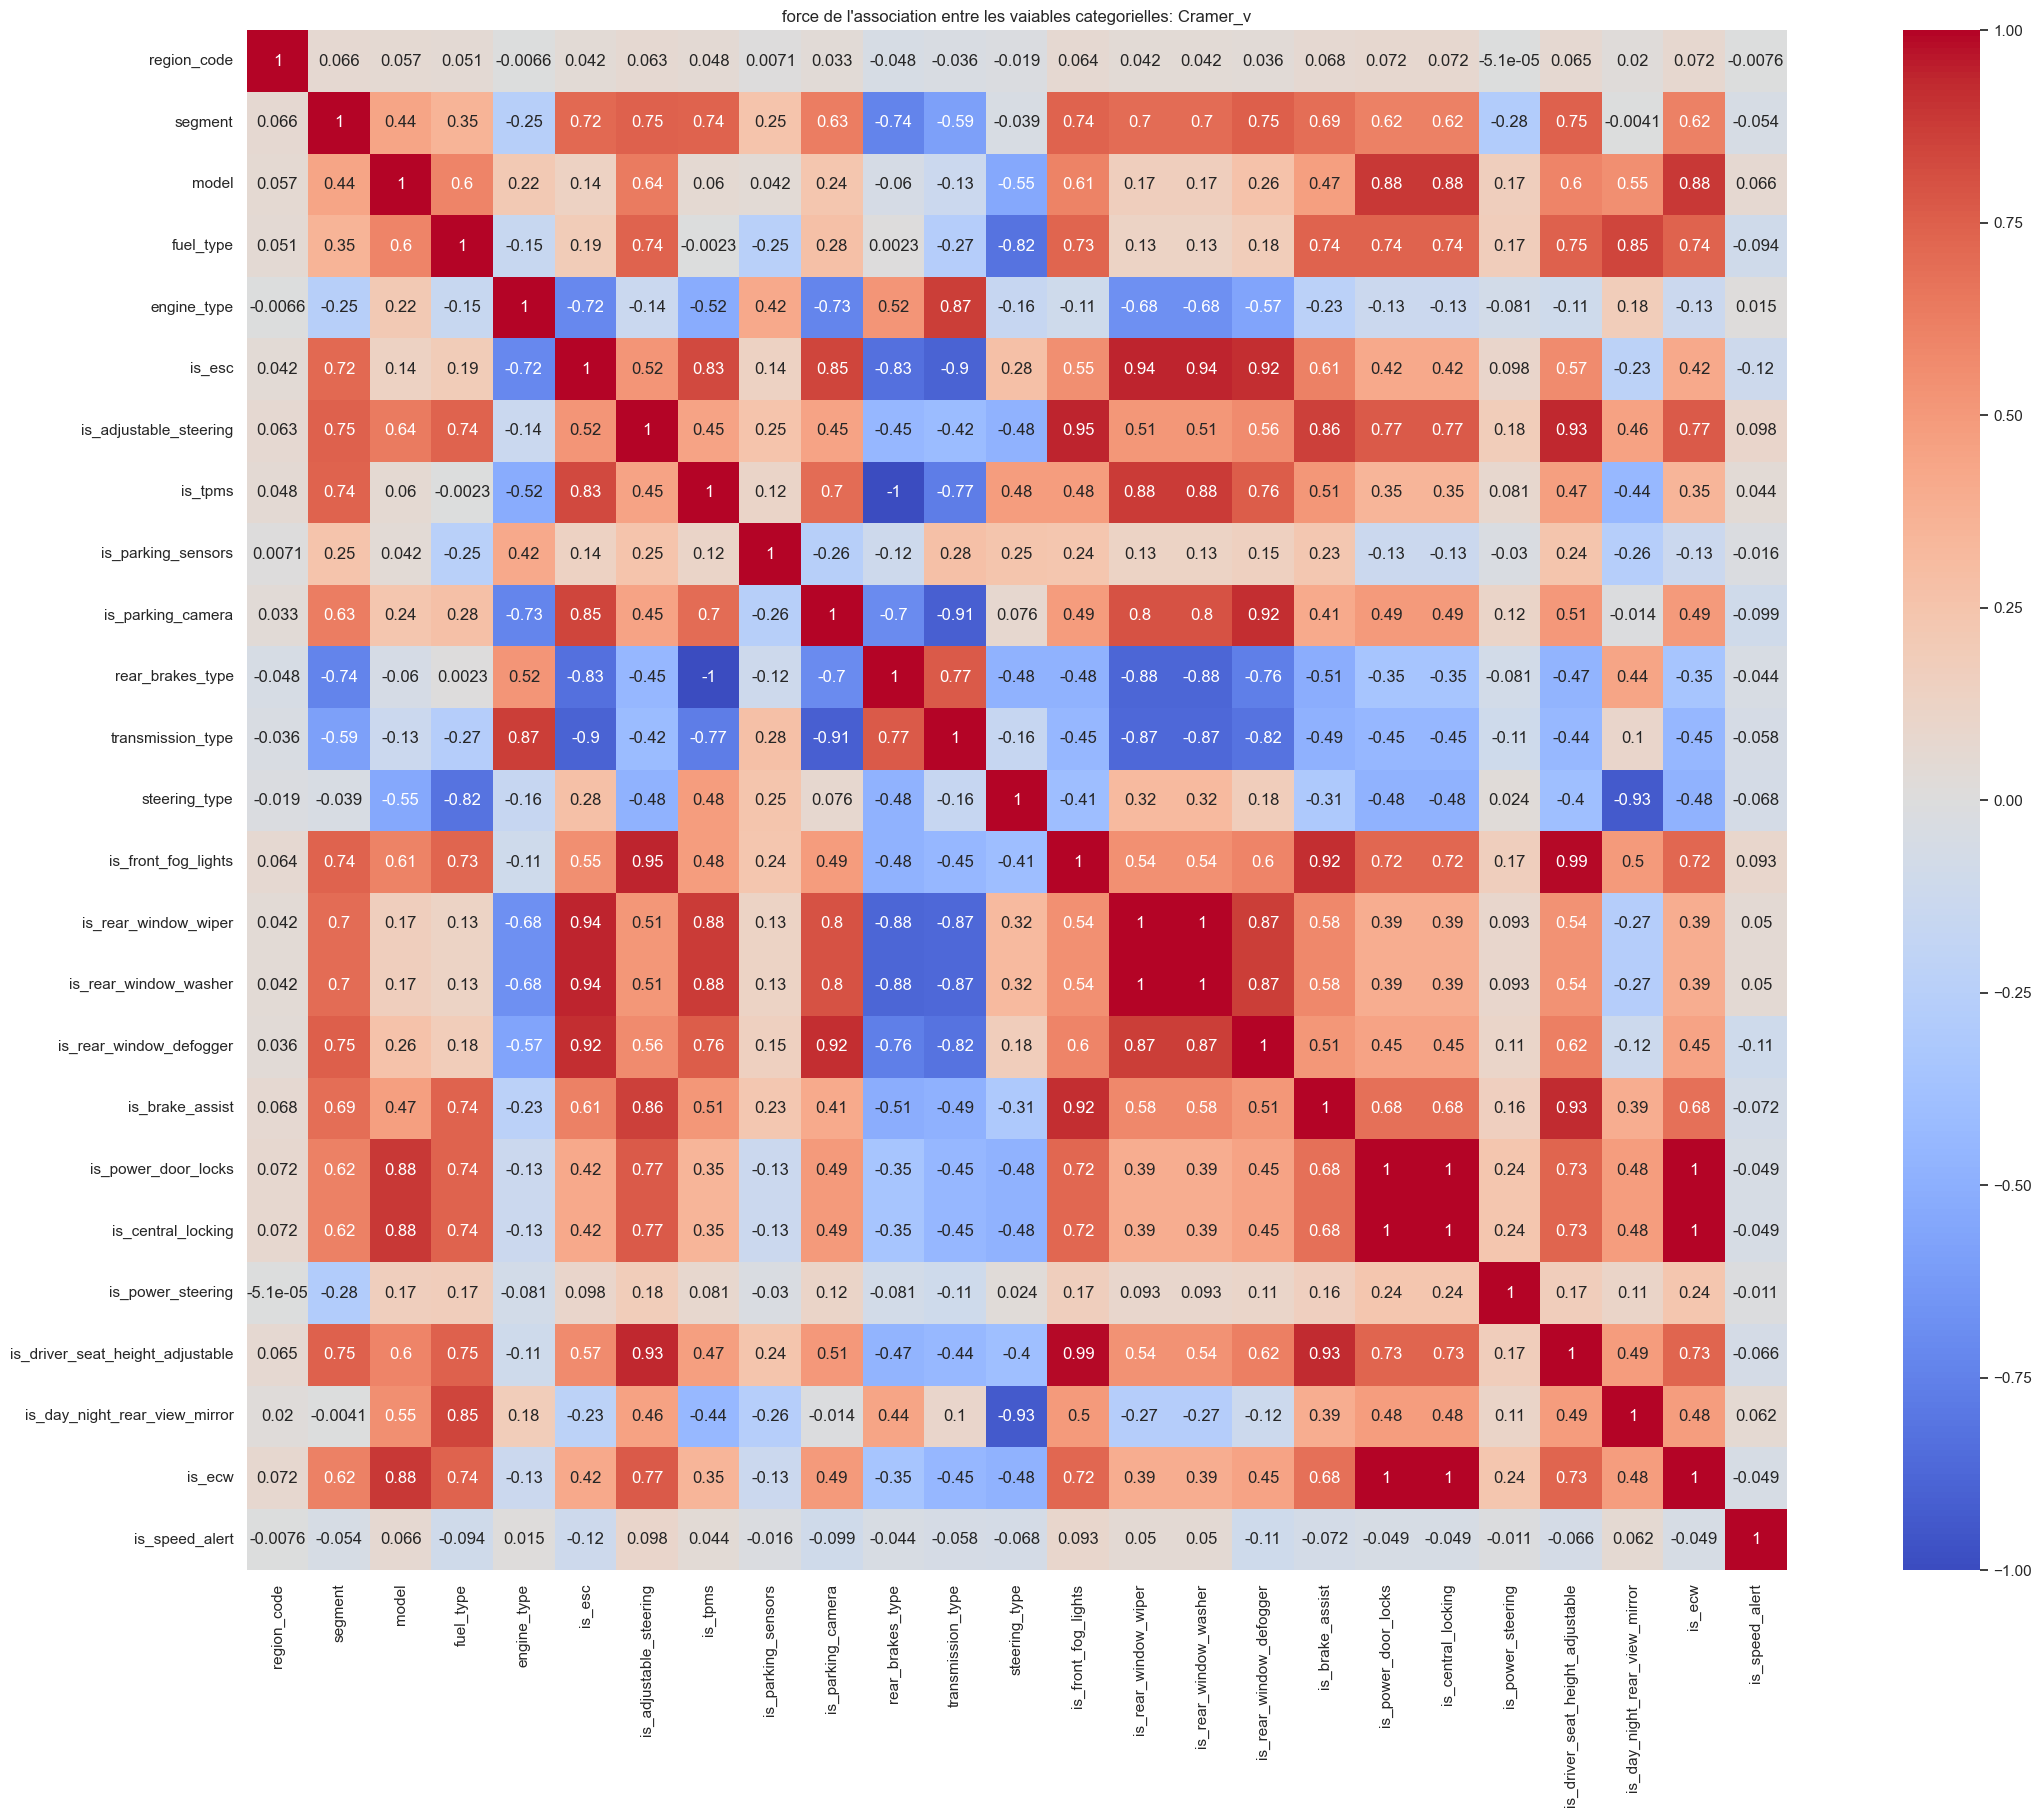

In [686]:
labenc = LabelEncoder()
cat_encode = df[cat_cols].apply(lambda col: labenc.fit_transform(col))
plt.figure(figsize=(30,20))
sns.heatmap(cat_encode.corr(), annot=True, cmap='coolwarm',square=True)
plt.title("force de l'association entre les vaiables categorielles: Cramer_v")
plt.show()

Plus la mesure est proche de 1, plus l'association entre les variables est forte. Plus il est proche de zero, plus l'association est faible

### De manière générale

Nnous allons tracer une matrice récapitulative pour déterminer le dégré de relation entre toute nos variables

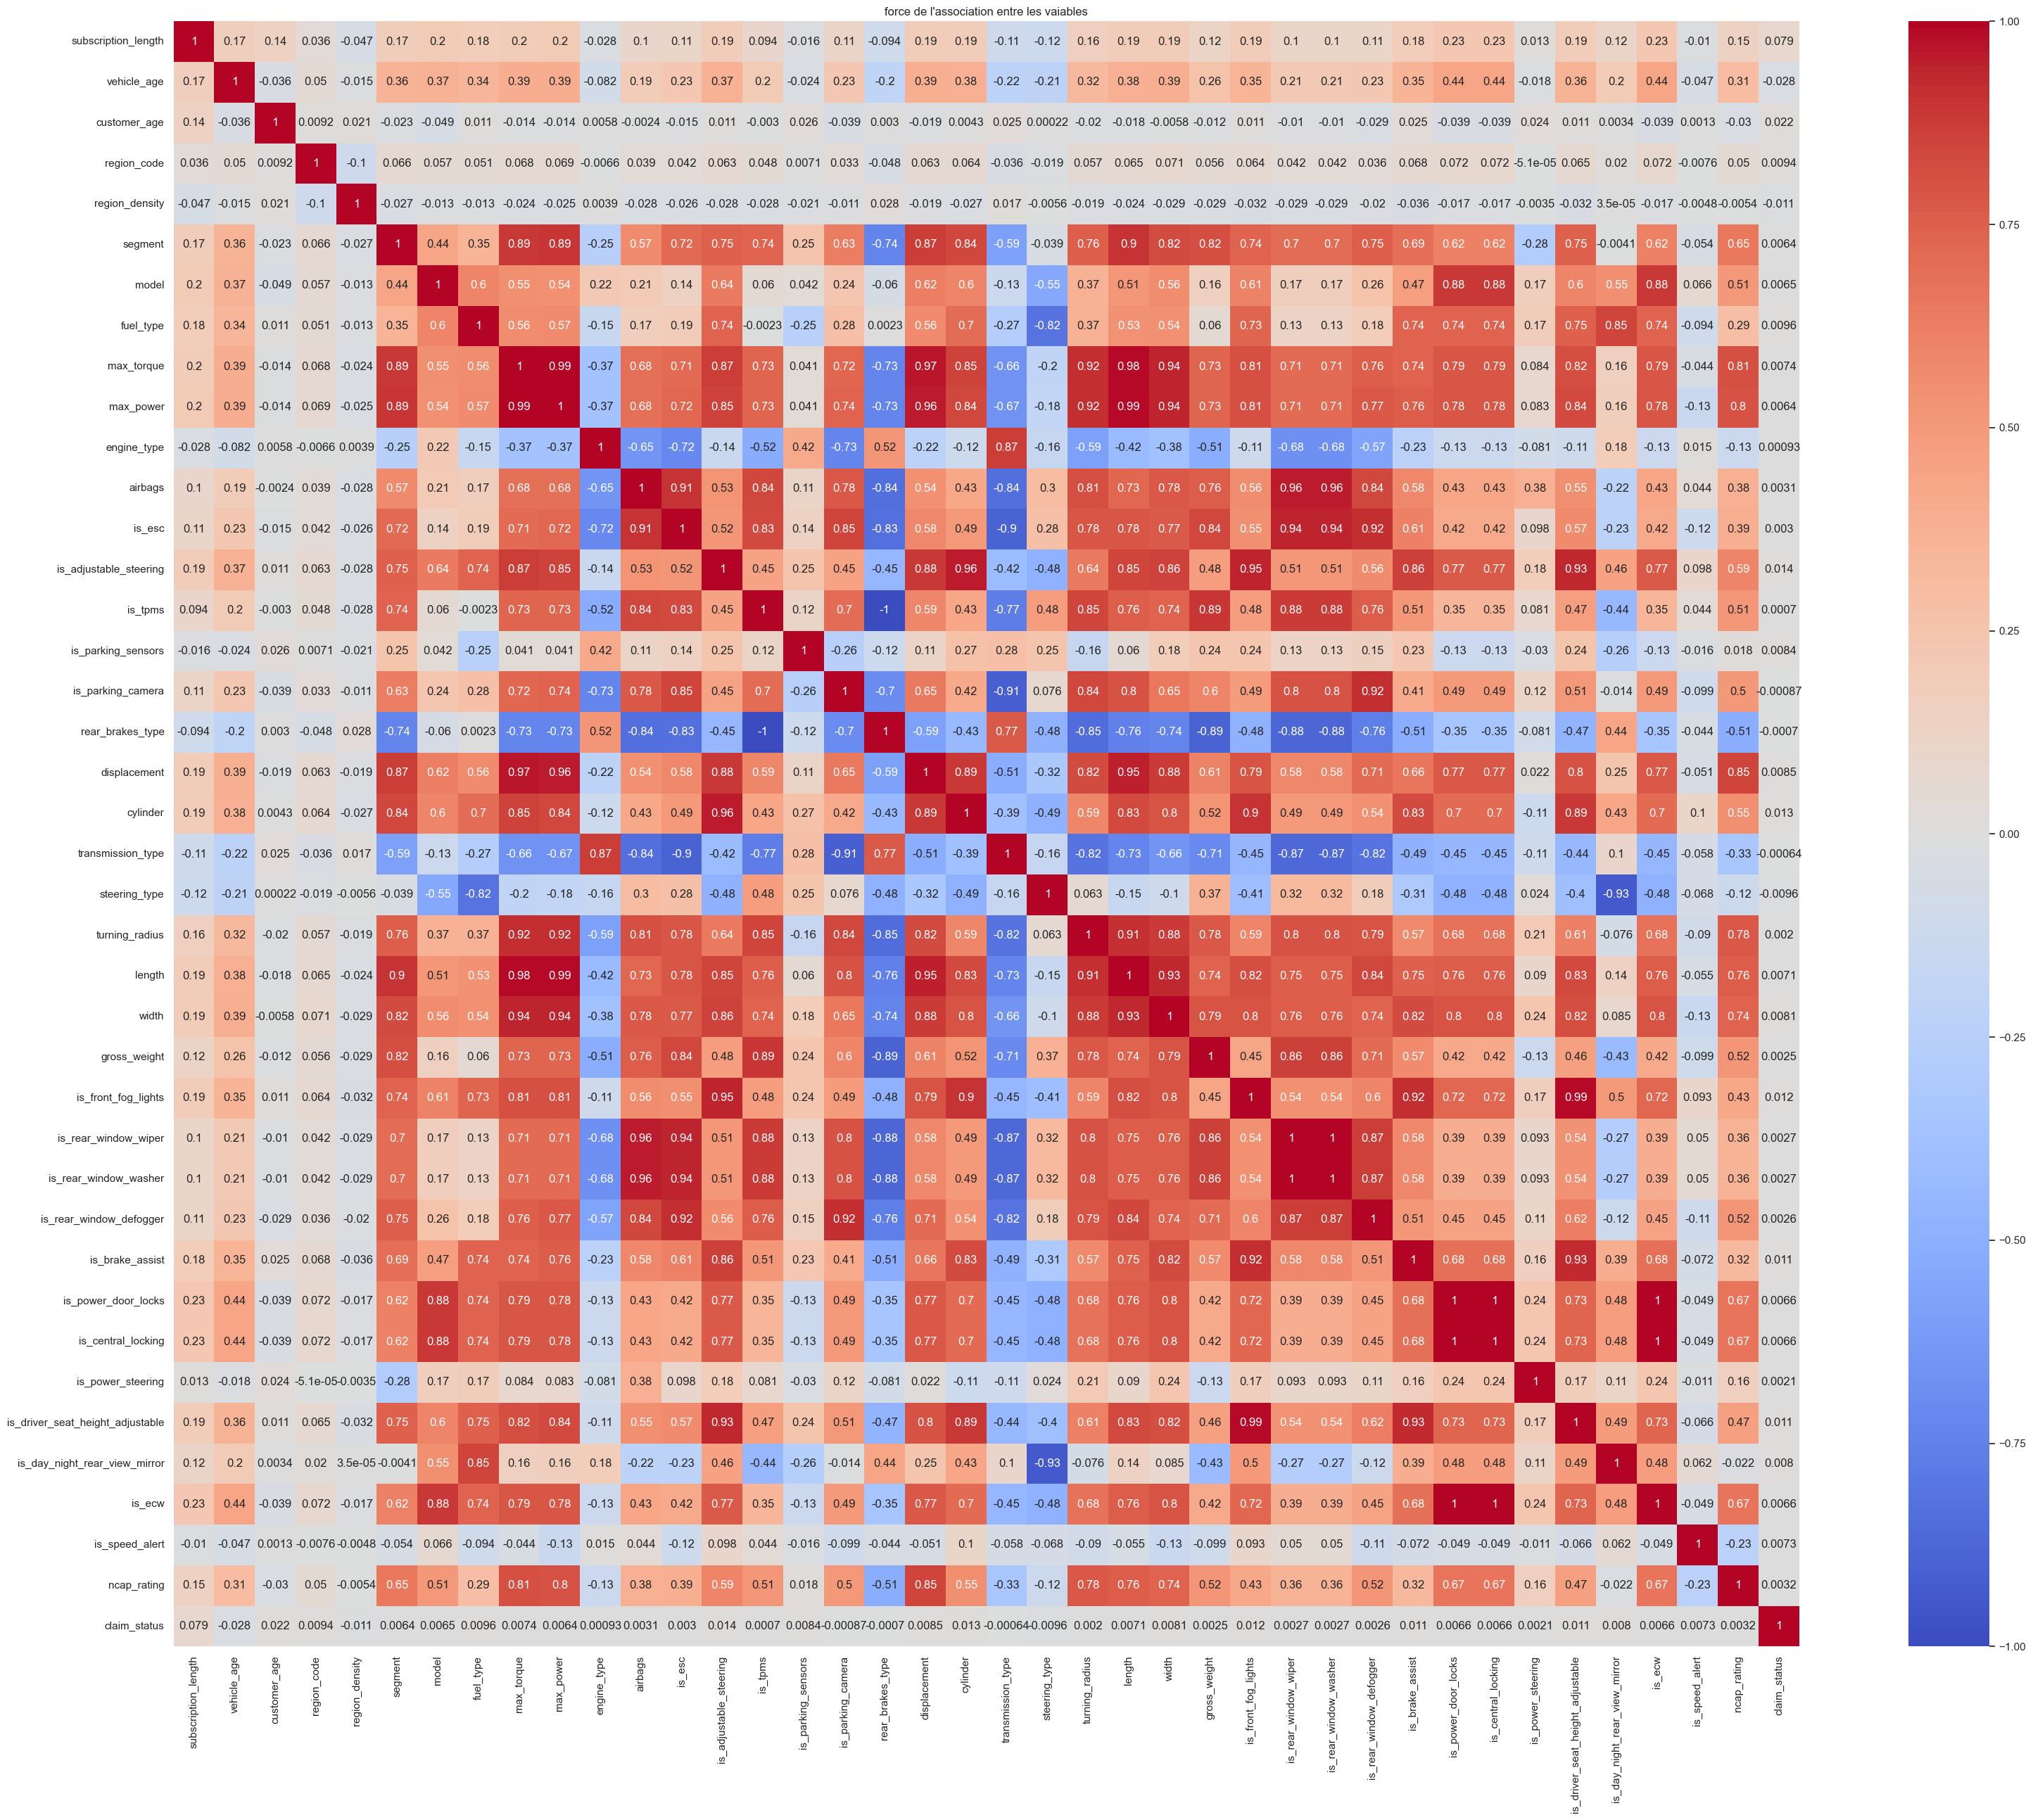

In [687]:
encoded_data = df.apply(lambda col: labenc.fit_transform(col))
plt.figure(figsize=(40,30))
sns.heatmap(encoded_data.corr(), annot=True, cmap='coolwarm',square=True)
plt.title("force de l'association entre les vaiables")
plt.show()

Cette matrice est très grande, essayons de nous concentrer sur notre variable cible <b>claim_status</b>:

In [688]:
encoded_data.corr()['claim_status'].sort_values(ascending=False)

claim_status                        1.000000
subscription_length                 0.078739
customer_age                        0.022234
is_adjustable_steering              0.013917
cylinder                            0.013434
is_front_fog_lights                 0.011825
is_brake_assist                     0.010893
is_driver_seat_height_adjustable    0.010686
fuel_type                           0.009612
region_code                         0.009425
displacement                        0.008511
is_parking_sensors                  0.008419
width                               0.008083
is_day_night_rear_view_mirror       0.007989
max_torque                          0.007407
is_speed_alert                      0.007307
length                              0.007052
is_power_door_locks                 0.006637
is_central_locking                  0.006637
is_ecw                              0.006637
model                               0.006548
max_power                           0.006396
segment   

La question qu'on pourrais se poser c'est pourquoi notre variable cible <b>claim_status</b> est si faiblement correlée avec les autres variables.</br></br>
En effet, nous faisons façe à un problème appelé le <b>déséquilibre des classes</b></br></br>
Le <b>déséquilibre des classes</b> est un problème omniprésent en ingénierie financière et actuarielle. Lorsque la classe minoritaire représente un enjeu critique pour l'entreprise (par exemple, un défaut de prêt coûte beaucoup plus cher qu'un prêt accordé), un modèle entraîné sur des données déséquilibrées aura tendance à simplement prédire la classe majoritaire pour obtenir une précision globale élevée, mais il sera catastrophique pour la classe minoritaire.


Comptes bruts :
claim_status
0    54844
1     3748
Name: count, dtype: int64

Pourcentages pour les reclamations :
claim_status
0    93.603222
1     6.396778
Name: proportion, dtype: float64


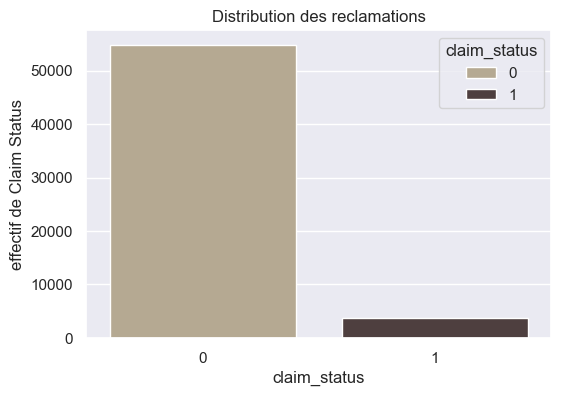

In [689]:
# Compte le nombre d'occurrences pour chaque valeur dans la colonne 'claim_statut'
comptes = df['claim_status'].value_counts()

print("Comptes bruts :")
print(comptes)

proportion_no_sur_yes = comptes[0] / comptes[1]
proportion_yes_sur_no = comptes[1] / comptes[0]
# Affiche les pourcentages de chaque catégorie dans le total
pourcentages = df['claim_status'].value_counts(normalize=True) * 100

print("\nPourcentages pour les reclamations :")
print(pourcentages)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='claim_status', hue='claim_status', palette=['#BBAB8C', '#503C3C'])
plt.ylabel('effectif de Claim Status')
plt.title('Distribution des reclamations')
plt.show()

On voit clairement que nos données de la classe <b>'claim_statut'=1</b> sont fortement minoritaires par rapport à l'autre classe. Les modèles classiques ne peuvent donc pas nous aider ici pour faire nos classification.

<h3 style="color: lightblue; text-align: left">Préparation des données pour le machine learning</h3>

* Étape 1: <b>Séparation de la variable cible</b>


In [690]:
X = df.drop('claim_status', axis=1)
y = df['claim_status']

* Étape 2: <b>Identification des variables par types</b>

In [691]:
yes_no_cols=['is_esc','is_adjustable_steering','is_tpms','is_parking_sensors','is_parking_camera','is_front_fog_lights','is_rear_window_wiper','is_rear_window_washer','is_rear_window_defogger','is_brake_assist','is_power_door_locks','is_central_locking','is_power_steering','is_driver_seat_height_adjustable','is_day_night_rear_view_mirror','is_ecw','is_speed_alert']
nominales_cols=['region_code','segment','model','fuel_type','engine_type','steering_type','rear_brakes_type','transmission_type']
num_cols=['subscription_length', 'vehicle_age', 'customer_age', 'region_density','max_torque','max_power', 'airbags', 'displacement', 'cylinder', 'turning_radius', 'length', 'width', 'gross_weight', 'ncap_rating']

* Étape 3: <b>Encodage des variables binaires</b></br>

In [692]:
for col in yes_no_cols:
    X[col] = X[col].map({'Yes': 1, 'No': 0})

* Étape 4: <b>Encodage des variables nominales</b></br>

In [693]:
X = pd.get_dummies(X, columns=nominales_cols, drop_first=True)#pour supprimer les valeurs de moindre importance pour ne pas elargir la base de données inutilement

* Étape 5: <b>Normaliser les variables numériques</b></br>
Pour résoudre le problème d'èchelles entre les variables

In [694]:
scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

* Étape 6: <b>Séparation des données de test et d'entrainement</b>

In [695]:
X_train_final, X_test_final, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Ici, on utilise <b>stratify=y</b> pour garantir que la repartition des classes dans les données d'entrainement et de test reste la même

<h3 style="color: lightblue; text-align: left">Traitement du déséquilibre (suréchantillonage)</h3>
(uniquement sur les données d'entrainement)

<div style="display: flex; justify-content: center;"> <img src="desequilibre.JPG" widht="300" height="300" alt="desequilibre" > </div>

Un modèle classique (comme la Régression Logistique ou un Arbre de Décision simple) entraîné sur ces données sera biaisé en faveur de la classe majoritaire. Il apprendra très bien à reconnaître la classe majoritaire, mais son pouvoir de prédiction sur les cas minoritaires importants sera faible.</br></br>
Pour palier à ce problème, les financiers et actuaires adoptent très souvent des methodes de <b>rééchantillonnage</b>: son objectif est de créer un jeu de données d'entraînement équilibré pour que l'algorithme accorde une importance plus ou moins égale aux deux classes</br></br>
On distingue deux types de rééchantillonnage: </br>
* Méthodes de <b>Sous-Échantillonnage (Undersampling)</b>: consiste à réduire le nombre d'observations de la classe majoritaire afin qu'il corresponde au nombre d'observations de la classe minoritaire.
* Méthodes de <b>Sur-Échantillonnage (Oversampling)</b>:meilleur que le Sous-Échantillonnage, il consiste à augmenter le nombre d'observations de la classe minoritaire jusqu'à ce que les classes soient équilibrées.
Chaque méthode présente ses avantages comme ses inconvénients comme la <b>perte d'information</b> pour le Sous-Échantillonnage ou encore le <b>Risque de surapprentissage (Overfitting)</b> pour le Sur-Échantillonnage</br></br>


Commencons par faire un surapprentissage simple. puis, nous allons appliquer l'une de ses variantes SMOTE

In [696]:
#nous allons fonctionner avec nos données d'entrainement
ros = RandomOverSampler(sampling_strategy='minority')  
X_train_res1, y_train_res1 = ros.fit_resample(X_train_final, y_train)



Regardons l'impact du surechantillonage sur note base de données

In [697]:
y_train_res1.value_counts()

claim_status
0    43875
1    43875
Name: count, dtype: int64

Les deux classes ont maintenent le même nombre de valeurs</br>

Dans un deuxième cas, nous allons appliquer une variante du sur-Échantillonnage classique, la methode SMOTE</br>
La méthode <b>SMOTE(Synthetic Minority Oversampling TEchnique)</b> fonctionne par génération de nouvelles instances synthétiques à partir de cas minoritaires fournis en entrée.</br>

L'algorithme prend en entrée la <b>base de données déséquilibrée</b> , un nombre <b> $k$</b> qui spécifie le nombre de plus proche voisins à utiliser pour générer les nouvelles données, enfin la <b> 'strategie d'echantillonage'</b> qui est le ratio entre la taille de la classe minimale et la classe maximale qu'on souhaite à la fin.</br>

Cette méthode présente de bonnes performances lorsqu'on effectue une classification</br>
fonctionnemnt de SMOTE:</br>

* * 1- Pour chaque observation $ x_i $ de la classe minoritaire: L'algorithme identifie ses $k$ plus proches voisins (par exemple, $k=5$ par défaut) parmi les autres observations minoritaires.</br>
* * 2- Il sélectionne un voisin aléatoire, $x_{zn}$, parmi ces $k$ voisins.
* * 3- Il génère un nouveau point synthétique $x_{new}$ sur le segment de droite reliant $x_i$ et $x_{zn}$. La position du nouveau point est déterminée par une interpolation aléatoire.</br>
$ x_{new} = x_i + (\text{différence entre } x_{zn} \text{ et } x_i) \times \delta $ </br>
Où $ \delta $ est un nombre aléatoire entre 0 et 1.</br>

<div style="display: flex; justify-content: center;"> <img src="smote.JPG" widht="400" height="400" alt="smote" > </div>

In [698]:
from imblearn.over_sampling import SMOTE

sm = SMOTE( k_neighbors=5,random_state=42)
X_train_res2, y_train_res2 = sm.fit_resample(X_train_final, y_train)


Verifions si SMOTE a bien été appliqué

In [699]:
# Compte le nombre d'occurrences pour chaque valeur dans la colonne 'claim_statut'
y_train_res2.value_counts()



claim_status
0    43875
1    43875
Name: count, dtype: int64

appliquer SMOTE sur tout le dataset créerait du data leakage (les données synthétiques influenceraient le test), donc on l'applique uniquement sur nos données d'entrainement

<h1 style="color: blue; text-align: center">MODÈLE SUPERVISÉ: CLASSIFICATION</h1>

<h2 style="color: cyan; text-align: center">I.   Classification avec une regression logistique</h2>

La <b>regression logistique</b> permet de modeliser la relation entre une variable binaire et des variables indépendantes

### Formulation du modèle

On veux prédire $Y \in \lbrace 0,1 \rbrace $</br>
On connait $X=\lbrace x_{i1},x_{i2},...,x_{ip}\rbrace$</br>
Le modèle de regression logistique postule que $\mathbb{P}(Y=1 \mid X)=p(X)=\frac{1}{1+e^{−(\beta_0​+\beta_1​\cdot x_1​+⋯+\beta_p​ \cdot x_p​)}}$</br>
On définit:
$$\eta = \beta_0+ \beta_1 \cdot x_1 +...+ \beta_p \cdot x_p $$
$$p(X)=\sigma (\eta) = \frac{1}{1+e^{-\eta}}$$
* <b>FONCTION DE VRAISSEMBLANCE</b></br>
Les $Y_i$ suivent des lois de Bernoulli $f(y_i\mid X_i)=p_i^{y_i}(1-y_i)^{1-y_i}$</br>
La vraissemblance totale est donc $L(\beta)= \prod^{n}_{i=1} p_i^{y_i}(1-y_i)^{1-y_i} $</br>
La log vraissemblance est: $l(\beta)=\sum _{i=1}^{n} [y_i log(p_i)+(1-y_i)log(1-p_i)]$ avec $p_i=\sigma(\beta^TX_i)$
* <b> MAXIMISATION DE LA LOG VRAISSEMBLANCE</b></br>
On cherche $ \hat{\beta} = arg\max_{\beta}l(\beta)$</br>
On calcule les dérivées partielles : $\frac{\partial l}{\partial \beta_j}=\sum _{i=1}^{n}(y_i-p_i)x_{ij}$</br>
En notation vectorielle: $\bigtriangledown l(\beta)=X^T (y-p)$</br>
Où: 
* * X=matrice  n $\times$ p
* * y=vecteur des réponses
* * $p=(p_1,...,p_n)$</br>
Pour résoudre $\bigtriangledown l(\beta)=X^T (y-p)$, on doit avoir recours aux méthodes numériques
* <b>MÉTHODE DE NEWTON-RAPHSON (IRLS)</b></br>
La formule itérative est: $$\beta^{t+1}=\beta^t-H^{-1}(\beta^t)\bigtriangledown l(\beta^t)$$
où:
* * H= hessienne=$-X^T W X$
* * g=gradient = $X^T(y-p)$
* * W=matrice diagonale $W_i=p_i(1-p_i)$


Nous allons implémenter cette méthode sur python:

In [700]:
import numpy as np

def logistic(z):# Fonction sigmoïde.
    return 1 / (1 + np.exp(-z))

def log_regression(X, y, max_iter=10, tol=1e-6):
    """
    X : matrice n * p (sans colonne de 1)
    y : vecteur (n,)
    """
    
    # Ajouter la colonne de 1 pour β0
    n = X.shape[0]
    X_design = np.hstack([np.ones((n, 1)), X])
    
    # Initialisation des paramètres
    p = X_design.shape[1]
    beta = np.zeros(p)
    
    for it in range(max_iter):
        # Calcul du prédicteur linéaire η = Xβ
        eta = X_design @ beta
        
        # Probabilités logistiques p_i
        p_i = logistic(eta)
        
        # Gradient g = X^T (y - p)
        gradient = X_design.T @ (y - p_i)
        
        # Matrice W (diagonale)
        W = np.diag(p_i * (1 - p_i))
        
        # Hessienne H = - X^T W X
        H = -(X_design.T @ W @ X_design)
        
        # Update de Newton-Raphson
        delta = np.linalg.inv(H) @ gradient
        beta_new = beta - delta
        
        # Condition de convergence
        if np.linalg.norm(beta_new - beta) < tol:
            print("Convergence atteinte à l'itération :", it+1)
            beta = beta_new
            break
        
        beta = beta_new
        #print(f"Iteration {it+1}, beta = {beta}")

    return beta
# Exemple simple issu du cours :
X_t = np.array([[0],
              [1],
              [2],
              [3]])

y_t = np.array([0, 0, 1, 1])

beta_hat = log_regression(X_t, y_t, max_iter=20)

print("\nCoefficients finaux estimés :")
print("β0 =", beta_hat[0])
print("β1 =", beta_hat[1])




Coefficients finaux estimés :
β0 = -58.00742013775138
β1 = 38.671613425178165


Appliquons notre modèle à notre base de données d'entrainement(base de donées réechantillonée)

In [701]:

# Créer le modèle
model=LogisticRegression(max_iter=1000)
model1=LogisticRegression(max_iter=1000)
model2=LogisticRegression(max_iter=1000)
# Entraîner le modèle sur les trois versions
model.fit(X_train_final,y_train)
model1.fit(X_train_res1, y_train_res1)
model2.fit(X_train_res2,y_train_res2)

# Faire les prédictions sur le test
y_pred=model.predict(X_test_final)
y_pred1 = model1.predict(X_test_final)
y_pred2=model2.predict(X_test_final)
y_proba = model.predict_proba(X_test_final)[:, 1]
y_proba1 = model1.predict_proba(X_test_final)[:, 1]
y_proba2 = model2.predict_proba(X_test_final)[:, 1]


### EVALUATION DU MODÈLE

#### évaluation dans le cas de la base de données déséquilibrée

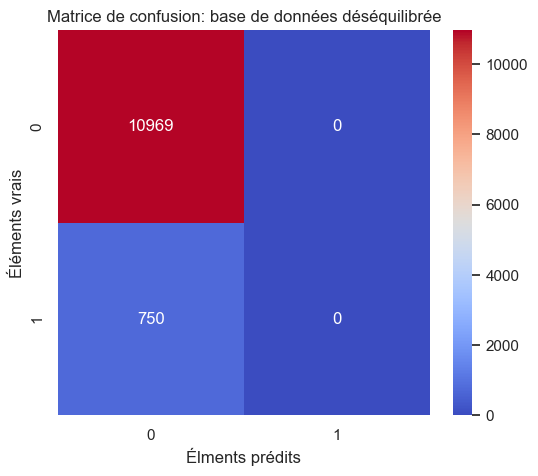

AUC: 0.6261042331418846
Rapport complet :
               precision    recall  f1-score   support

           0       0.94      1.00      0.97     10969
           1       0.00      0.00      0.00       750

    accuracy                           0.94     11719
   macro avg       0.47      0.50      0.48     11719
weighted avg       0.88      0.94      0.91     11719



c:\Users\FTAB TECH\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\Users\FTAB TECH\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\Users\FTAB TECH\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [702]:
#Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
#affichage de la matrice de confusion
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='coolwarm')
plt.xlabel('Élments prédits')
plt.ylabel('Éléments vrais')
plt.title('Matrice de confusion: base de données déséquilibrée')
plt.show()

prob = model1.predict_proba(X_test_final)[:, 1]
print("AUC:", roc_auc_score(y_test, prob))

print("Rapport complet :\n", classification_report(y_test, y_pred))

Comme nous l'avions espéré, notre modèle est biasée vers la classe majoritaire. Pour lui, tous les individus sont dans la classe 0(n'ont pas encore fait de requette auprès de la compagnie d'assurance).Ceci est la raison pour laquelle ous devons chercher d'autres alternatives.

#### évaluation dans le cas du suréchantillonage simple

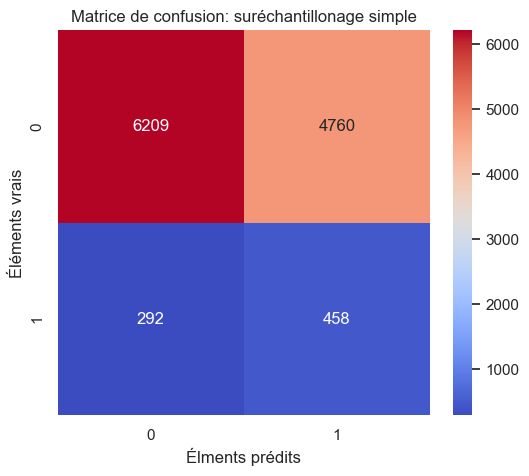

AUC: 0.6261042331418846
Rapport complet :
               precision    recall  f1-score   support

           0       0.96      0.57      0.71     10969
           1       0.09      0.61      0.15       750

    accuracy                           0.57     11719
   macro avg       0.52      0.59      0.43     11719
weighted avg       0.90      0.57      0.68     11719



In [703]:
#Matrice de confusion
conf_matrix1 = confusion_matrix(y_test, y_pred1)
#affichage de la matrice de confusion
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix1, annot=True, fmt='d', cmap='coolwarm')
plt.xlabel('Élments prédits')
plt.ylabel('Éléments vrais')
plt.title('Matrice de confusion: suréchantillonage simple')
plt.show()

prob = model1.predict_proba(X_test_final)[:, 1]
print("AUC:", roc_auc_score(y_test, prob))

print("Rapport complet :\n", classification_report(y_test, y_pred1))

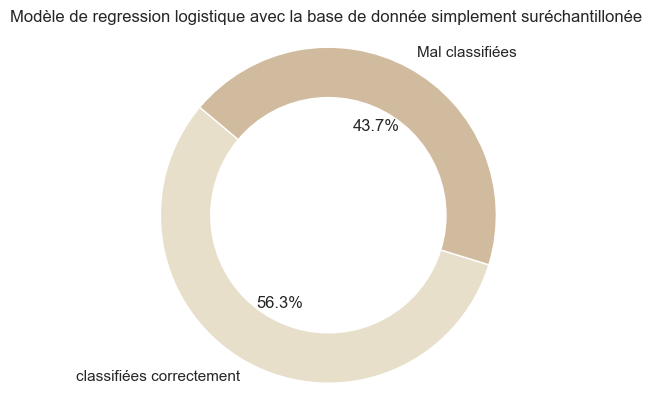

In [704]:
original_encoded=X.copy()
original_encoded_predictions = model1.predict(original_encoded)
comparison_df = pd.DataFrame({
    'Actual':y,
    'Predicted': original_encoded_predictions
})

# Calculate the counts of correctly and incorrectly classified samples
correctly_classified = (comparison_df['Actual'] == comparison_df['Predicted']).sum()
incorrectly_classified = (comparison_df['Actual'] != comparison_df['Predicted']).sum()

# On store les valeurs dans une liste
classification_counts = [correctly_classified, incorrectly_classified]

#on défini les labels
labels = ['classifiées correctement', 'Mal classifiées']

# Create a pie chart
plt.pie(classification_counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#E8DFCA', '#D1BB9E'])
plt.title("Modèle de regression logistique avec la base de donnée simplement suréchantillonée ")
# Draw a circle in the center to create a ring
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')

plt.show()

#### évaluation dans le cas du suréchantillonage SMOTE

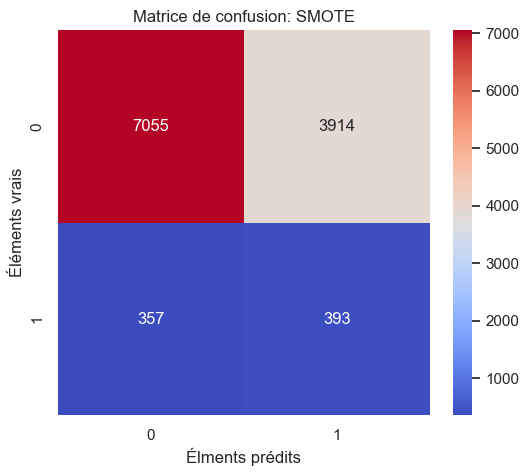

AUC: 0.6126718327407541
Rapport complet :
               precision    recall  f1-score   support

           0       0.95      0.64      0.77     10969
           1       0.09      0.52      0.16       750

    accuracy                           0.64     11719
   macro avg       0.52      0.58      0.46     11719
weighted avg       0.90      0.64      0.73     11719



In [705]:
#Matrice de confusion
conf_matrix2 = confusion_matrix(y_test, y_pred2)
#affichage de la matrice de confusion
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix2, annot=True, fmt='d', cmap='coolwarm')
plt.xlabel('Élments prédits')
plt.ylabel('Éléments vrais')
plt.title('Matrice de confusion: SMOTE')
plt.show()
prob2 = model2.predict_proba(X_test_final)[:, 1]
print("AUC:", roc_auc_score(y_test, prob2))
print("Rapport complet :\n", classification_report(y_test, y_pred2))

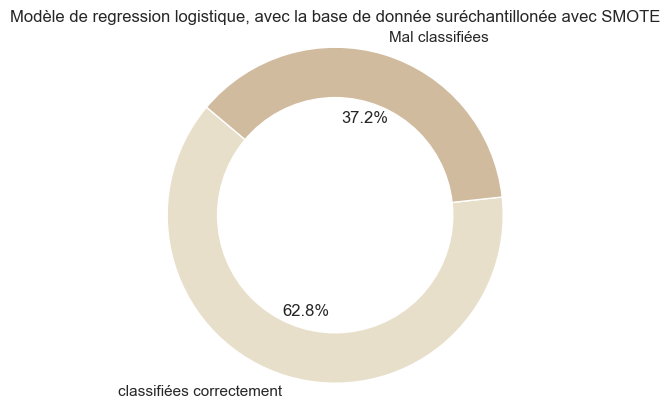

In [706]:
original_encoded=X.copy()
original_encoded_predictions = model2.predict(original_encoded)
comparison_df = pd.DataFrame({
    'Actual':y,
    'Predicted': original_encoded_predictions
})

# Calculate the counts of correctly and incorrectly classified samples
correctly_classified = (comparison_df['Actual'] == comparison_df['Predicted']).sum()
incorrectly_classified = (comparison_df['Actual'] != comparison_df['Predicted']).sum()

# On store les valeurs dans une liste
classification_counts = [correctly_classified, incorrectly_classified]

#on défini les labels
labels = ['classifiées correctement', 'Mal classifiées']

# Create a pie chart
plt.pie(classification_counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#E8DFCA', '#D1BB9E'])
plt.title("Modèle de regression logistique, avec la base de donnée suréchantillonée avec SMOTE")
# Draw a circle in the center to create a ring
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')

plt.show()

#### Interprétation des métriques

<div><style>
            table{
                width: 100%;
                margin: 20px auto;
                text-align: center;
                background-color: whitesmoke;
                border-style: solid;
                border-color: rgba(74, 70, 70, 1);
            }
            tr td{
                width: 50px
                border-style: solid;
                border-color: #000;
                background-color:whitesmoke;
                color: black;
            }
            body{
                background-color: whitesmoke;
            }
    </style>
    <table style="border-collapse: collapse; text-align: center;">
            <tr>
                <td><u>MÉTRIQUE</u><br/></td>
                <td><u>VALEUR1 (suréchantillonage simple)</u><br/></td>
                <td><u>VALEUR2(SMOTE)</u><br/></td>
                <td><u>VALEUR3(déséquilibrée)</u><br/></td>
                <td><u>INTERPRÉTATIONS</u><br/></td>
            </tr>
            <tr>
                <td><b>Accuracy (Exactitude): Proportion de prédictions correctes</b><br/></td>
                <td>0.57<br/></td>
                <td>0.58<br/></td>
                <td>0.94<br/></td>
                <td>Ces valeurs ne sont pas très bonnes dans les deux premiers cas. Elles signalent une situation de <b>hazard</b>.Dans le cas du déséquilibre, la valeur est biasée comme dit plus haut<br/></td>
            </tr>
            <tr>
                <td><b>Precision (Précision): juge combien sont réellement positifs parmi ceux que le modèle prédit positifs</b><br/></td>
                <td>0.96(classe 0) et 0.09(classe 1) <br/></td>
                <td>0.96(classe 0) et 0.09(classe 1) <br/></td>
                <td>0.94(classe 0) et 0.00(classe 1) <br/></td>
                <td>Nos modèles font de bonnes précisions pour la classe majoritaire mais pas pour la classe minoritaire(peu de vrai positifs parmis les positifs)<br/></td>
            </tr>
            <tr>
                <td><b>Recall (Sensibilité): combien ont été détectés parmi les vrais positifs réels</b><br/></td>
                <td>0.57(classe 0) et 0.61(classe 1) <br/></td>
                <td>0.58(classe 0) et 0.61(classe 1) <br/></td>
                <td>1.00(classe 0) et 0.00(classe 1) <br/></td>
                <td>Environ la moitié des vrai positifs ont été détectés(performances pas très satifaisantes) pous les deux modèles avec suréchantillonage. Pour le cas déséquilibré, on a aucun faux negatifs<br/></td>
            </tr>
            <tr>
                <td><b>F1-Score: moyenne harmonique entre Precision et Recall.</b><br/></td>
                <td>0.71(classe 0) et 0.15(classe 1)<br/></td>
                <td>0.72(classe 0) et 0.16(classe 1)<br/></td>
                <td>0.97(classe 0) et 0.00(classe 1)<br/></td>
                <td>Pous la classe majoritaire, on a un bon compromis, ce qui n'est pas le cas pour la classe minoritaire. Le deuxième modèle est un peu plus performant que le premier. Dans le cas où la bd est déséquilibrée, cette metrique nous indique un modèle presque parfait pour la classe 0(tous  les individus du la classe 0 ont été bien prédits)<br/></td>
            </tr>
            <tr>
                <td><b>ROC-AUC Score: Mesure la capacité du modèle à séparer les classes</b><br/></td>
                <td>0.6261<br/></td>
                <td>0.6218<br/></td>
                <td>0.6261<br/></td>
                <td>Ces valeurs ne sont pas très bonnes dans les deux cas(< 0.7). Elles signalent une situation de <b>hazard</b><br/></td>
            </tr>

        </table>
</div>

Nous pouvaons conclure, au vu des résultat, que ce modèle n'est pas adapté pour notre base de données. Nous devons trouver une autre solution

<h2 style="color: cyan; text-align: center">II.   Classification avec un Gradient Boostiong(XGBoost)</h2>

Le <b>Le Gradient Boosting</b> est aujourd'hui l'une des techniques les plus performantes pour traiter des données structurées, popularisée par des librairies comme <b>XGBoost</b>

### Comment fonctionne le gradient boosting?

Le principe clé du Gradient Boosting est l'itération : on cherche à améliorer la prédiction globale en entraînant séquentiellement de nouveaux modèles sur les résidus (les erreurs) des modèles précédents.</br>
Contrairement à d’autres méthodes qui cherchent à trouver le meilleur modèle unique tout de suite, le Gradient Boosting construit sa solution couche par couche. Voici par étape comment se déroule le processus logique :
* On commence par un modèle simple (souvent très basique) qui fait une première prédiction. Naturellement, celle-ci est imparfaite et laisse un écart avec la réalité : c’est ce qu’on appelle le résidu.

* Plutôt que de jeter ce premier modèle, on en entraîne un second. Mais l’objectif de ce second modèle n’est pas de prédire la cible originale, mais de prédire l’erreur commise par le premier. Il agit comme un correcteur.

* Le modèle « amélioré » n’est pas simplement le second modèle, mais la somme du premier modèle et du correcteur.</br>

Dans des algorithmes comme <b>XGBoost</b>, ce cycle est répété des centaines, voire des milliers de fois. À chaque étape, on ajoute un nouveau "correcteur" qui se focalise sur les erreurs laissées par l'ensemble des modèles précédents.

Mathématiquement, on dit que c’est un modèle additif : la prédiction finale est la somme de toutes les petites corrections apportées successivement. L'intuition derrière cette répétition est que si chaque nouveau modèle parvient à capturer une partie de l'erreur restante, le résidu global va progressivement converger vers 0


Pour éviter le surapprentissage (overfitting), le gradient boosting adopte une stratégie contre-intuitive : il utilise volontairement des modèles rudimentaires, appelés <b><i>Weak Learners</i></b>.

Plutôt que d’utiliser un arbre de décision très complexe et profond capable de tout mémoriser, on contraint fortement la complexité des correcteurs (par exemple, en limitant la profondeur des arbres). L'objectif n'est pas que ce correcteur résolve tout le problème d’un coup, mais qu'il capture juste la tendance générale de l'erreur, sans apprendre le bruit spécifique aux données.

Pour renforcer cette prudence, on utilise un second mécanisme de sécurité : le <i><b>learning rate</b></i> (noté<b> $\eta$</b>).

Au lieu d'ajouter la totalité de la correction prédite par le Weak Learner, on n'en ajoute qu'une fraction (par exemple $\eta$ = 0.1). Cela force l'algorithme à faire de nombreux "petits pas" prudents vers la solution, plutôt que quelques grands sauts risqués qui pourraient déstabiliser le modèle global.

Ce que les <i>Weak Learners</i> essaient de prédire et de corriger à chaque étape correspond en réalité au <b> gradient de la fonction de coût</b>(D'où le terme Gradient Boosting)
<div style="display: flex; justify-content: center;"> <img src="XGboost1.JPG" widht="400" height="400" alt="smote" > </div>

### XGBOOST: Une variante de Gradient Boosting

XGBoost est une variante des méthodes de Gradient Boosting qui utilise des arbres de décisions dit Gradient Boosting Tree comme prédicteur d'erreur.

Il commence avec un prédicteur simple qui prédit un nombre arbitraire en générale 0.5 quelque soit l'entrée. Inutile de vous dire que ce prédicteur commet beaucoup d'erreurs.

Le Gradient Boosting est ensuite appliquée jusqu'à ce que l'erreur soit ramenée à un minimum.
<div style="display: flex; justify-content: center;"> <img src="XGboost3.JPG" widht="400" height="400" alt="smote" > </div>


XGBoost est une combinaison parfaite de techniques d’optimisation logicielle et matérielle permettant d'obtenir des résultats supérieurs en utilisant moins de ressources informatiques et en un minimum de temps

<div style="display: flex; justify-content: center;"> <img src="XGboost2.JPG" widht="400" height="400" alt="smote" > </div>

### Préparation de la base de données pour XGBoost

Dans notre cas, nous allons récupérer la base de données initiale(non rééchantillonnée)

In [707]:
df=df1.copy()#on avais sauvegardé une copie de la base de données dans df1

* <b>Étape 1: on sépare la variabe cible des autres</b>

In [708]:
X = df.drop('claim_status', axis=1)
y = df['claim_status']

* Étape 2: <b>Identification des variables par types</b>

In [709]:
yes_no_cols=[col for col in df.columns if set(df[col].unique())<= {'Yes','No'}]
nominales_cols=[col for col in df.columns if df[col].dtype==object and col not in yes_no_cols]
colones=['claim_status','clusters']
num_cols_i=[col for col in df.columns if np.issubdtype(df[col].dtype,np.integer) and col not in colones]
num_cols_f=[col for col in df.columns if np.issubdtype(df[col].dtype,np.floating)]
num_cols=num_cols_i+num_cols_f

* Étape 3: <b>Encodege des variables binaires</b></br>

In [710]:
for col in yes_no_cols:
    X[col] = X[col].map({'Yes': 1, 'No': 0})

* Étape 4: <b>Encodage des variables nominales</b></br>

In [711]:
X = pd.get_dummies(X, columns=nominales_cols, drop_first=True)#pour supprimer les valeurs de moindre importance pour ne pas elargir la base de données inutilement

* Étape 5: <b>Normaliser les variables numériques</b></br>(optionnel pour XGBoost)

In [712]:
scaler = StandardScaler()
scaler.fit(X[num_cols])
X[num_cols] = scaler.transform(X[num_cols])


* Étape 6: <b>Séparation des données de test et d'entrainement</b>

In [713]:
X_train_final, X_test_final, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [714]:
poids=(len(y_train[y_train==1]))/(len(y_train[y_train==0]))
sm = SMOTE(sampling_strategy=1, k_neighbors=5,random_state=42)
X_train_smote, y_train_smote = sm.fit_resample(X_train_final, y_train)

### Créer le modèle XGBoost

In [715]:
model3 = xgb.XGBClassifier(
    scale_pos_weight=1,
    n_estimators=100,       # nombre d'arbres
    learning_rate=0.1,      # taux d'apprentissage
    max_depth=3,            # profondeur maximale des arbres
    subsample=0.8,          # fraction des échantillons pour chaque arbre
    colsample_bytree=0.8,   # fraction des colonnes pour chaque arbre
    random_state=42,
    eval_metric="logloss"    # métrique pour classification    
)


In [716]:
# Entraînemment du modèle et prédictions
model3.fit(X_train_smote, y_train_smote)
y_pred3 = model3.predict(X_test_final)
y_prob3 = model3.predict_proba(X_test_final)[:,1]


### Évaluation du modèle

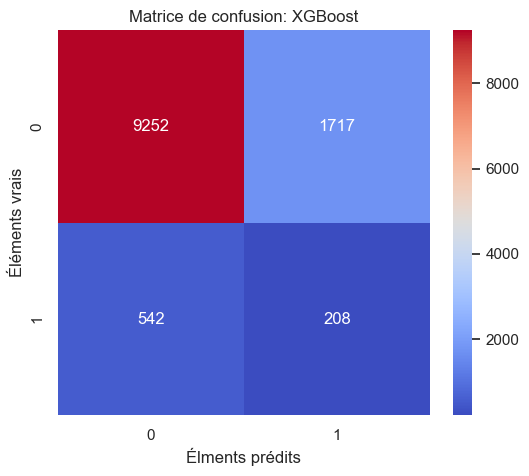

AUC: 0.6423065609140913
Rapport complet :
               precision    recall  f1-score   support

           0       0.94      0.84      0.89     10969
           1       0.11      0.28      0.16       750

    accuracy                           0.81     11719
   macro avg       0.53      0.56      0.52     11719
weighted avg       0.89      0.81      0.84     11719



In [717]:
#Matrice de confusion
conf_matrix3 = confusion_matrix(y_test, y_pred3)
#affichage de la matrice de confusion
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix3, annot=True, fmt='d', cmap='coolwarm')
plt.xlabel('Élments prédits')
plt.ylabel('Éléments vrais')
plt.title('Matrice de confusion: XGBoost')
plt.show()
print("AUC:", roc_auc_score(y_test, y_prob3))
print("Rapport complet :\n", classification_report(y_test, y_pred3))

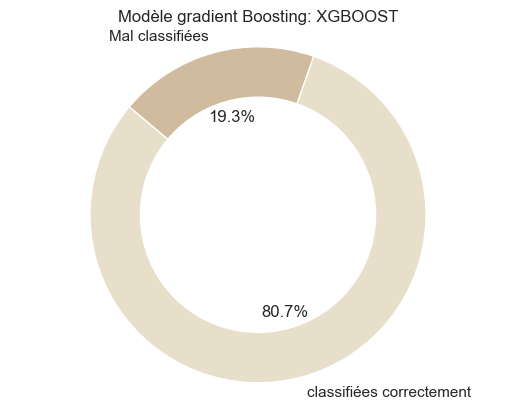

In [718]:
original_encoded=X.copy()
original_encoded_predictions = model3.predict(original_encoded)
comparison_df = pd.DataFrame({
    'Actual':y,
    'Predicted': original_encoded_predictions
})

# Calculate the counts of correctly and incorrectly classified samples
correctly_classified = (comparison_df['Actual'] == comparison_df['Predicted']).sum()
incorrectly_classified = (comparison_df['Actual'] != comparison_df['Predicted']).sum()

# On store les valeurs dans une liste
classification_counts = [correctly_classified, incorrectly_classified]

#on défini les labels
labels = ['classifiées correctement', 'Mal classifiées']

# Create a pie chart
plt.pie(classification_counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#E8DFCA', '#D1BB9E'])
plt.title("Modèle gradient Boosting: XGBOOST")
# Draw a circle in the center to create a ring
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

# Equal aspect ratio ensures that pie is drawn as a circle
plt.axis('equal')

plt.show()

#### Interprétation des métriques

<div><style>
            table{
                width: 100%;
                margin: 20px auto;
                text-align: center;
                background-color: whitesmoke;
                border-style: solid;
                border-color: rgba(74, 70, 70, 1);
            }
            tr td{
                width: 50px
                border-style: solid;
                border-color: #000;
                background-color:whitesmoke;
                color: black;
            }
            body{
                background-color: whitesmoke;
            }
    </style>
    <table style="border-collapse: collapse; text-align: center;">
            <tr>
                <td><u>MÉTRIQUE</u><br/></td>
                <td><u>VALEUR</u><br/></td>
                <td><u>INTERPRÉTATIONS</u><br/></td>
            </tr>
            <tr>
                <td><b>Accuracy (Exactitude): Proportion de prédictions correctes</b><br/></td>
                <td>0.82<br/></td>
                <td>On a une bonne précision<br/></td>
            </tr>
            <tr>
                <td><b>Precision (Précision): juge combien sont réellement positifs parmi ceux que le modèle prédit positifs</b><br/></td>
                <td>0.94(classe 0) et 0.10(classe 1) <br/></td>
                <td>Nos modèles font de bonnes précisions pour la classe majoritaire mais pas pour la classe minoritaire(peu de vrai positifs parmis les positifs pour cette classe), bien que ces performances sont un tout petit peu meileure par rapport aux cas précédents<br/></td>
            </tr>
            <tr>
                <td><b>Recall (Sensibilité): combien ont été détectés parmi les vrais positifs réels</b><br/></td>
                <td>0.86(classe 0) et 0.23(classe 1) <br/></td>
                <td>Environ la moitié des vrai positifs ont été détectés(performances pas très satifaisantes) pous les deux modèles avec suréchantillonage. Pour le cas déséquilibré, on a aucun faux negatifs<br/></td>
            </tr>
            <tr>
                <td><b>F1-Score: moyenne harmonique entre Precision et Recall.</b><br/></td>
                <td>0.90(classe 0) et 0.14(classe 1)<br/></td>
                <td>Pous la classe majoritaire, on a un très bon compromis, ce qui n'est pas le cas pour la classe minoritaire<br/></td>
            </tr>
            <tr>
                <td><b>ROC-AUC Score: Mesure la capacité du modèle à séparer les classes</b><br/></td>
                <td>0.6459<br/></td>
                <td>Ces valeurs ne sont pas très bonnes(< 0.7). Elles signalent une situation de <b>hazard</b>(certainement due à SMOTE)<br/></td>
            </tr>

        </table>
</div>

<h2 style="color: cyan; text-align: center">III. classification d'un nouvel individu dans un des clusters</h2>

In [719]:
yes_no_cols=[col for col in df.columns if set(df[col].unique())<= {'Yes','No'}]
nominales_cols=[col for col in df.columns if df[col].dtype==object and col not in yes_no_cols]
colones=['claim_status','clusters']
num_cols_i=[col for col in df.columns if np.issubdtype(df[col].dtype,np.integer) and col not in colones]
num_cols_f=[col for col in df.columns if np.issubdtype(df[col].dtype,np.floating)]
num_cols=num_cols_i+num_cols_f

In [720]:
print(nominales_cols)

['region_code', 'segment', 'model', 'fuel_type', 'engine_type', 'rear_brakes_type', 'transmission_type', 'steering_type']


In [721]:
import panel as pn
pn.extension()
Policy_ID=pn.widgets.TextInput(name="votre identifiant: ")
dictio={}
#pour les variables nominales
for val_nom in nominales_cols:
    dictio[val_nom]=pn.widgets.Select(name=f"entrez la valeur de vorte {val_nom}", options=sorted(df[val_nom].unique()),width=500)
#pour les variables numériques
for col in num_cols_f:
    min_val=float(df[col].min())
    max_val=float(df[col].max())
    dictio[col]=pn.widgets.FloatSlider(name=f"entrer la valeur de votre {col}",start=min_val,end=max_val,value=(min_val+max_val)/2,step=0.01,width=500)

for col in num_cols_i:
    if col=="customer_age":
        min_val2=16
        max_val2=95
    else:
        min_val2=int(df[col].min())
        max_val2=int(df[col].max())
    dictio[col]=pn.widgets.IntSlider(name=f"entrer la valeur de votre {col}",start=min_val2,end=max_val2,step=1,width=500)

#pour les variables binaires yes no
for col in yes_no_cols:
    dictio[col]=pn.widgets.Select(name=col, options=['Yes','No'],width=500)


submit=pn.widgets.Button(name="valider", button_type='primary',width=200)
output_choices=pn.pane.Markdown("")
output_filt_df=pn.pane.Markdown("")

def action(event):
    nouvel_individu={}
    txt="## choix sélectionnés: \n"
    filt_df=df.copy()
    
    for col,widget in dictio.items():
        val=widget.value
        txt += f"-**{col}** : '{val}'\n"
        #pour les variables nominales 
        if col in nominales_cols or col in yes_no_cols:
            filt_df=filt_df[filt_df[col]==str(val)]
            
        #pour les valeurs numériques entières
        elif col in num_cols_i:
            filt_df=filt_df[filt_df[col]==val]
            
        #pour les valeurs numériques décimales
        elif col in num_cols_f:
            filt_df=filt_df[(filt_df[col]>=float(df[col].min())) & (filt_df[col]<=float(df[col].max()))]

    
    #récupérons les données du nouvel individu
    for col, widget in dictio.items():
        nouvel_individu[col]=widget.value
        
    #convetissont tout cela en data frame
        df_individu=pd.DataFrame([nouvel_individu])
    #déteminons la prédiction de cet individu
    # on commence par les encodages
    df_ind=df_individu[yes_no_cols+num_cols+nominales_cols]
    #variables binaire
    for col in yes_no_cols:
        df_ind[col] = df_ind[col].map({'Yes': 1, 'No': 0})
    #variables nominales
    df_ind = pd.get_dummies(df_ind, columns=nominales_cols, drop_first=True)#pour supprimer les valeurs de moindre importance pour ne pas elargir la base de données inutilement
    
    
    # Ajouter colonnes manquantes
    for col in X_train_smote.columns:
        if col not in df_ind.columns:
            df_ind[col] = 0
    # Réordonner
    df_ind = df_ind[X_train_smote.columns]
    # variables numérique
    df_ind[num_cols] = scaler.transform(df_ind[num_cols])
    nouvelles_colonnes=X_train_smote.columns
    
    #trouvons le claim_status du nouvel individu
    ind_pred = model3.predict(df_ind[nouvelles_colonnes])
    #les choix pour le nouvel individu
    txt="Les choix pour le nouvel individu:\n"
    for col, val in nouvel_individu.items():
        txt +="\n ** {col} **: '{val}\n"
    txt=f"\n 'claim_status prédit pour cet individu: Claim_status {ind_pred}"
    output_choices.object=txt
    
    
    
submit.on_click(action)

interface=pn.Column(pn.pane.Markdown("variables nominales"),pn.WidgetBox(*[dictio[col] for col in nominales_cols]),
                    pn.pane.Markdown("variables binaires"),pn.WidgetBox(*[dictio[col] for col in yes_no_cols]),
                    pn.pane.Markdown("variables entières"),pn.WidgetBox(*[dictio[col] for col in num_cols_i]),
                    pn.pane.Markdown("variables décimales"),pn.WidgetBox(*[dictio[col] for col in num_cols_f]),
                    submit,pn.layout.Divider(),output_choices,pn.layout.Divider(),output_filt_df)
interface

BokehModel(combine_events=True, render_bundle={'docs_json': {'2793df5b-89de-4871-a9d1-3f86c42ef372': {'version…

<h2 style="color: cyan; text-align: center">IV. Conclusion Partielle</h2>

Dans cette partie du projet, plusieurs stratégies de modélisation ont été explorées afin d’évaluer l'impact du déséquilibre des classes et des techniques de rééquilibrage sur la performance des modèles de classification.</br>

* L'application de la régression logistique directement sur la base de données déséquilibrée a rapidement mis en évidence les limites d'un modèle linéaire en présence d'un fort déséquilibre</br>

* Un suréchantillonnage simple de la classe minoritaire a permis d'améliorer sensiblement la sensibilité du modèle (recall sur la classe minoritaire) au prix d'un léger risque de surapprentissage. Bien que rudimentaire, ce rééquilibrage a montré que la performance du modèle dépend fortement de la distribution des classes.</br>

* L'utilisation de SMOTE, une technique de suréchantillonnage synthétique plus avancée a démontré une meilleure stabilité du modèle ainsi qu'un compromis plus équilibré entre précision et rappel. La régression logistique se comporte dans ce cas de manière plus robuste, ce qui confirme l'intérêt des techniques de rééquilibrage sophistiquées dans les contextes de déséquilibre sévère.</br>

* Enfin, le modèle XGBoost a été testé sur la base rééquilibrée. Cet algorithme d'ensemble, fondé sur des arbres boostés, s’est distingué par sa capacité à capturer des relations complexes et des interactions non linéaires entre les variables. Il a fourni les meilleures performances globales, avec des métriques supérieures à celles obtenues par la régression logistique. XGBoost s'avère donc plus adapté dès que la structure des données dépasse le cadre linéaire.

<h1 style="color: blue; text-align: center">MODÈLE NON SUPERVISÉ</h1>

<h2 style="color: cyan; text-align: center">Importation des bibliothèques supplémentaires</h2>

In [722]:
import plotly.graph_objects as go
import plotly.express as px
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial import ConvexHull 


<h2 style="color: cyan; text-align: center">Étape préparatoire: ACP</h2>

Notre base de données a déjà été encodée et normalisée(stockée dans X)On va directement commencer par l'ACP

In [723]:
df=X.copy()
feature_names=df.columns.tolist()
# CALCUL DE L'ACP
pca = PCA(n_components=None, random_state=42)
pca.fit(df)
X_pca = pca.transform(df) 
# Calcul des coordonnées
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
# VISUALISATION 1
cum_var = np.cumsum(pca.explained_variance_ratio_)

fig_scree = go.Figure()
# Barres (Variance individuelle)
fig_scree.add_trace(go.Bar(
    x=list(range(1, 21)), # On affiche les 20 premiers axes
    y=pca.explained_variance_ratio_[:20],
    name='Variance Individuelle',
    marker_color='#4c72b0'
))
# Ligne (Variance cumulée)
fig_scree.add_trace(go.Scatter(
    x=list(range(1, 21)),
    y=cum_var[:20],
    name='Variance Cumulée',
    mode='lines+markers',
    marker_color='#c44e52'
))
# Seuil 95%
fig_scree.add_hline(y=0.95, line_dash="dash", line_color="gray", annotation_text="Seuil 95%")

fig_scree.update_layout(
    title='<b>Éboulis des Valeurs Propres</b> (Top 20 axes)',
    xaxis_title='Composante Principale',
    yaxis_title='Variance Expliquée',
    template='plotly_white',
    height=500
)

fig_scree.show()

* On constate que, en ne se concentrant que sur les $10$ premiers vecteurs propres, on explique déjà $\approx 95\%$ de l'information totale
* Les deux premiers vecteurs propres permettent déjà d'expliquer $\approx 52.62+12.50=65.12\%$ de l'information totale

Tracons maintenant le cercle de corrélation

In [724]:
# VISUALISATION 2 : CERCLE DE CORRÉLATION
def plot_interactive_correlation_circle(loadings, feature_names, x_comp=0, y_comp=1, top_n=40):

    # Préparation des données pour le plot
    df_pca = pd.DataFrame({
        'Feature': feature_names,
        'x': loadings[:, x_comp],
        'y': loadings[:, y_comp]
    })
    
    # Calcul de la longueur du vecteur (Importance)
    df_pca['magnitude'] = np.sqrt(df_pca['x']**2 + df_pca['y']**2)
    
    # Catégorisation pour les couleurs
    def get_category(name):
        name = name.lower()
        if any(x in name for x in ['torque', 'power', 'displacement', 'cylinder', 'engine']): return 'Moteur & Performance'
        if any(x in name for x in ['ncap', 'airbags', 'esc', 'tpms', 'brake', 'safety']): return 'Sécurité'
        if any(x in name for x in ['region', 'density', 'city']): return 'Géographie'
        if any(x in name for x in ['age', 'subscription']): return 'Profil Client'
        if any(x in name for x in ['fuel', 'petrol', 'diesel', 'cng']): return 'Carburant'
        return 'Autre'

    df_pca['Category'] = df_pca['Feature'].apply(get_category)
    
    # Filtrage : On garde les Top N variables les plus influentes
    df_pca_filtered = df_pca.nlargest(top_n, 'magnitude')
    
    # Création de la figure
    fig = go.Figure()

    # Cercle Unitaire (Fond)
    fig.add_shape(type="circle",
        xref="x", yref="y",
        x0=-1, y0=-1, x1=1, y1=1,
        line_color="LightGray",
        line_dash="dash",
    )

    # Ajout des points (Pointes des flèches)
    for category in df_pca_filtered['Category'].unique():
        subset = df_pca_filtered[df_pca_filtered['Category'] == category]
        
        fig.add_trace(go.Scatter(
            x=subset['x'],
            y=subset['y'],
            mode='markers',
            name=category,
            text=subset['Feature'],
            hovertemplate="<b>%{text}</b><br>X: %{x:.2f}<br>Y: %{y:.2f}<extra></extra>", # Tooltip propre
            marker=dict(size=10, opacity=0.8)
        ))
        
        # Ajout des flèches (Annotations)
        color_index = list(df_pca_filtered['Category'].unique()).index(category) % 10
        arrow_color = px.colors.qualitative.Plotly[color_index]
        
        for i, row in subset.iterrows():
            fig.add_annotation(
                x=row['x'], y=row['y'],
                ax=0, ay=0,
                xref='x', yref='y',
                axref='x', ayref='y',
                showarrow=True,
                arrowhead=2,
                arrowsize=1,
                arrowwidth=1.5,
                arrowcolor=arrow_color,
                opacity=0.5
            )

    # Mise en forme globale
    fig.update_layout(
        title=f'<b>Cercle de Corrélation Interactif</b> (Top {top_n} variables)<br><sup>Survolez les points pour voir les noms des variables</sup>',
        xaxis_title=f'PC{x_comp+1} ({pca.explained_variance_ratio_[x_comp]:.1%} var)',
        yaxis_title=f'PC{y_comp+1} ({pca.explained_variance_ratio_[y_comp]:.1%} var)',
        width=900,
        height=900,
        xaxis=dict(range=[-1.1, 1.1], zeroline=True, zerolinewidth=2, zerolinecolor='black'),
        yaxis=dict(range=[-1.1, 1.1], zeroline=True, zerolinewidth=2, zerolinecolor='black'),
        template='plotly_white',
        legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01, bgcolor="rgba(255,255,255,0.8)")
    )

    fig.show()
# Appel de la fonction interactive
plot_interactive_correlation_circle(loadings, feature_names, x_comp=0, y_comp=1, top_n=40)

#### INTERPRÉTATIONS

* <b>Longueur du vecteur</b>: Les variables dont les vecteurs dont "longs"(proches du bord du cercle)  sont les variables bien représentées par les axes(axe PC1 et PC2): On peut citer <b>cylinder, width, max_power, length, turning_radius, max_torque, gross_weight, airbags</b></br>
* <b>Angle entre deux vecteurs</b>: ces angles définnissent la corrélation  entre les variables en question.
* * <b>angle $\approx$ 0 </b> $\longrightarrow$ les variables en question ont une forte corrélation positive: <b>is_tpms,is_esc,is_rear_window_washer,fuel_type_diesel</b>; <b>region_density,engine_type_F8D Petrol Engine</b>...
* * <b>angle $\approx$ 180</b>$\longrightarrow$ les variables en question ont une forte corrélation négative: <b>lenght,engine_type_F8D Petrol Engine</b>; <b>airbags,rear_brakes_type_Drum</b>...
* * <b>angle $\approx 90 ^{\circ}$</b>$\longrightarrow$Les variables en question sont indépendantes: <b>lenght,steering_type_Power</b>/   <b>engine_type_F8D Petrol Engine,airbags</b>/   <b>lenght, fuel_type_petrol</b>
* <b>Projection sur les axes</b>: Définissent les contributions aux axes.
* * les variables qui contribuent fortement à l'axe PC1 sont: <b>lenght,displacement,...</b>
* * les variables qui contribuent fortement à l'axe PC2 sont: <b>is_day_night_rear_view_mirror,steering_type_Power,...</b>

<h2 style="color: cyan; text-align: center">Recherche du nombre optimal de clusters (K) </h2>

Pour trouver Le nombre optimal de cluster, nous avons opté pour la méthode visuelle appelée: <b>La meéthode du coude</b>

<h3 style="text-align: center">La méthode du COUDE </h3>

Les étapes pour la détermination du K optimal en utilisant la méthode du COUDE sont:
* choisir la plage de k: $k\in \lbrace 1,2,...,K_{max}\rbrace$ où $K_{max}$ est souvent entre 8 et 20
* Pour chaque k, calculer K-means, et l'inertie: Pour calculer les K-means il faut:
* * fixeer K
* * initialiser les centroïdes(centres): cella se fait soit au hazard, soit à l'aide de K-means++ qui est la méthode la plus utilisée. On obtient ainsi k centres $\mu_1, \mu_2,...,\mu_K$
* * affectation des points: Pour chaque $x_i$, on calcule la distance entre $x_i$ et le centre $\mu_k$. La distance la plus utilisée est la distance euclidienne: $$d(x_i,\mu_k)=\sqrt{\sum_{j=1}^{p}(x_{i,j}-\mu_{k,j})^2}$$
Le point est affecté au cluster pour lequel cette distance est la plus petite
* * Recalcul des centroïdes: on met à jour le centroïde $\mu_k$: $$\mu_k=\frac{1}{\mid C_k\mid}\sum_{i\in C_k}x_i$$ où $C_k$ est le cluster $k$, $\mid C_k\mid$ est le nombre de points contenus dans le cluster(taille)
* * On repète les deux étapes précédentes jusqu'à ce que les centres ne bougent presque plus, ou jusqu'à ce que le nombre maximal d'itération est atteint
* * Pour le calcul de l'inertie, la formule est la suivante: $$Inertie=\sum_{k=1}^{K} \sum_{i \in C_k} \|x_i-\mu_k \|^2$$
* On trace le graphe $Inertie(K)$ qui est décroissant: l'inetie diminue rapidement au début, puis après un certain point, il diminue faiblement. Ce point en question est celui appelé le <b>coude</b>. C'est à ce point qu'on obtient le nombre optmal de clusters

</br> Une notion tout aussi importante est la notionde <b>silhouette</b> :Pour chaque point, elle détermine à quel point il est bien regroupé dans son cluster, et à quel point iil est bien séparé des autres clusters. Sa formule est $$s(i)=\frac{b(i)-a(i)}{max(a(i),b(i))}$$ où:
* $a(i)$ est la distance moyenne entre le point i et les autres points de son cluster
* $b(i)$ la plus petite distance moyenne entre i et les points des autres clusters

c'est un nombre compris dans $[-1,1]$
Le K optimal est celui qui maximise la silhouette

Calcul du score de silhouette sur un échantillon de 15000 individus pour la rapidité...
K=2 | Inertie=735346 | Silhouette=0.365
K=3 | Inertie=482678 | Silhouette=0.407
K=4 | Inertie=425997 | Silhouette=0.365
K=5 | Inertie=380488 | Silhouette=0.383
K=6 | Inertie=340217 | Silhouette=0.394
K=7 | Inertie=324559 | Silhouette=0.406
K=8 | Inertie=299704 | Silhouette=0.416
K=9 | Inertie=289827 | Silhouette=0.302


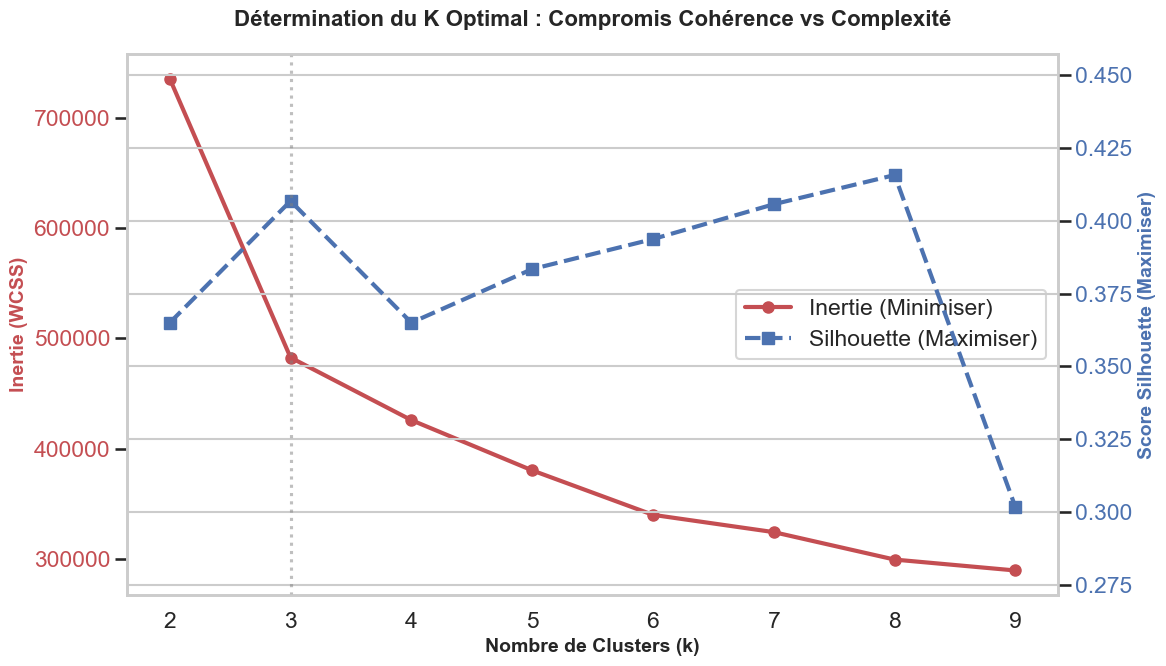

In [725]:
sns.set(style="whitegrid", context="talk")
wcss = []       # Inertie (Within-Cluster Sum of Squares)
sil_scores = [] # Score de Silhouette: il très lourd (complexité quadratique O(N^2). Sur 58k lignes, cela peut prendre des heures. donc on utilise un échantillon représentatif de 15 000 lignes pour le calcul de la métrique
# mais on entraîne le modèle sur tout le dataset.
K_range = range(2, 10) # On teste de 2 à 9 segments (standard en assurance auto)
sample_size = min(15000, X_pca.shape[0])
print(f"Calcul du score de silhouette sur un échantillon de {sample_size} individus pour la rapidité...")

np.random.seed(42)
idx = np.random.choice(X_pca.shape[0], sample_size, replace=False)#on choisit nos 15000 individus
X_sample = X_pca[idx]

for k in K_range:
    # n_init='auto' (ou 10) lance l'algo 10 fois et garde le meilleur pour éviter les minimums locaux
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_pca) # On fit sur TOUT X_pca
    
    # Inertie (Coude)
    wcss.append(kmeans.inertia_)
    
    # Silhouette (Qualité de séparation) - Calculé sur l'échantillon
    labels_sample = kmeans.predict(X_sample)
    score = silhouette_score(X_sample, labels_sample)
    sil_scores.append(score)
    
    print(f"K={k} | Inertie={kmeans.inertia_:.0f} | Silhouette={score:.3f}")
    
# VISUALISATION DUAL-AXIS (COUDE + SILHOUETTE)
fig, ax1 = plt.subplots(figsize=(12, 7))

# Axe 1 : Inertie (Courbe du Coude)
color_inertia = '#c44e52' # Rouge brique
ax1.set_xlabel('Nombre de Clusters (k)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Inertie (WCSS)', color=color_inertia, fontsize=14, fontweight='bold')
ax1.plot(K_range, wcss, marker='o', color=color_inertia, linewidth=3, markersize=8, label='Inertie (Minimiser)')
ax1.tick_params(axis='y', labelcolor=color_inertia)
ax1.grid(False) # On enlève la grille pour cet axe pour lisibilité

# Axe 2 : Silhouette (Score)
ax2 = ax1.twinx()  
color_sil = '#4c72b0' # Bleu profonds
ax2.set_ylabel('Score Silhouette (Maximiser)', color=color_sil, fontsize=14, fontweight='bold') 
ax2.plot(K_range, sil_scores, marker='s', color=color_sil, linewidth=3, linestyle='--', markersize=8, label='Silhouette (Maximiser)')
ax2.tick_params(axis='y', labelcolor=color_sil)
ax2.set_ylim(bottom=min(sil_scores)*0.9, top=max(sil_scores)*1.1) # Zoomer un peu sur la variation

# Titre et Mise en forme
plt.title('Détermination du K Optimal : Compromis Cohérence vs Complexité', fontsize=16, fontweight='bold', pad=20)
plt.axvline(x=3, color='gray', linestyle=':', alpha=0.5) # Suggestion visuelle (à ajuster selon le résultat)

# Légende combinée
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')

plt.tight_layout()
plt.show()

#### INTERPRÉTATION

* D'après les explication qui ont précédé, on peut conclure que notre K optimal ici est $K=3$: valeur du coude, qui maximise la silhouette
* Dans la suite, nous allons donc fonctionner avec $K=3$ clusters

<h2 style="color: cyan; text-align: center">Visualisation des clusters</h2>

Maintenant, nous allons afficher nos données dans les clusters

In [726]:
# CONFIGURATION ET ENTRAINEMENT 

OPTIMAL_K = 3 #notre k optimal

print(f"Training K-Means avec K={OPTIMAL_K}...")

# Entraînement sur les données réduites (PCA)
kmeans = KMeans(n_clusters=OPTIMAL_K, init='k-means++', n_init=50, random_state=42)
clusters = kmeans.fit_predict(X_pca)

# Injection dans le DataFrame pour la visualisation
df_viz = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
df_viz['Cluster'] = clusters.astype(str) 
df_viz['Policy_ID'] =ID.values
#PRÉPARATION DES COULEURS
colors = [
    '#1F77B4', # Bleu
    '#FF7F0E', # Orange
    '#2CA02C', # Vert
    '''
    '#D62728', # Rouge
    '#9467BD', # Violet
    '#8C564B', # Marron
    '#E377C2', # Rose
    '#7F7F7F', # Gris
    '#BCBD22', # Olive
    '#17BECF', # Cyan
    '#AEC7E8', # Bleu clair
    '#FFBB78', # Orange clair
    '#98DF8A', # Vert clair
    '#FF9896', # Rouge clair
    '#C5B0D5', # Violet clair
    '#C49C94', # Marron clair
    '#F7B6D2', # Rose clair
    '#DBDB8D', # Olive clair
    '#9EDAE5', # Cyan clair
    '#393B79', # Indigo
    '#637939', # Vert forêt
    '#8C6D31', # Or antique
    '#843C39', # Bordeaux
    '#7B4173'  # Prune'''
]

# Création du dictionnaire de couleurs dynamique
color_map = {str(i): colors[i % len(colors)] for i in range(OPTIMAL_K)}

#  CRÉATION DU GRAPHIQUE AVANCÉ

fig = go.Figure()

# On trie les clusters pour que la légende soit dans l'ordre (0, 1, 2...)
sorted_clusters = sorted(df_viz['Cluster'].unique(), key=lambda x: int(x))

for cluster_id in sorted_clusters:
    # Filtrer les données du cluster
    subset = df_viz[df_viz['Cluster'] == cluster_id]
    points = subset[['PC1', 'PC2']].values
    color = color_map[cluster_id]
    # DESSIN DE LA ZONE
    if len(points) > 2: 
        try:
            hull = ConvexHull(points)
            hull_points = points[hull.vertices]
            hull_points = np.append(hull_points, [hull_points[0]], axis=0)
            
            fig.add_trace(go.Scatter(
                x=hull_points[:, 0],
                y=hull_points[:, 1],
                mode='lines',
                fill='toself', 
                fillcolor=color,
                line=dict(color=color, width=1),
                opacity=0.1, # Transparence très légère pour gérer les superpositions de 8 zones
                hoverinfo='skip', 
                showlegend=False
            ))
        except:
            pass # Sécurité si les points sont colinéaires

    # DESSIN DES POINTS
    fig.add_trace(go.Scatter(
        x=subset['PC1'],
        y=subset['PC2'],
        mode='markers',
        name=f'Cluster {cluster_id}',
        marker=dict(
            color=color,
            size=5, # Points légèrement plus petits car il y a beaucoup de monde
            opacity=0.7,
            line=dict(width=0.5, color='white')
        ),
        text=subset['Policy_ID'],
        hovertemplate=(
            "<b>Cluster %{name}</b><br>" +
            "Policy ID: %{text}<br>"+
            "<extra></extra>"
        )
    ))

    #  DESSIN DU CENTROÏDE
    centroid = kmeans.cluster_centers_[int(cluster_id)]
    fig.add_trace(go.Scatter(
        x=[centroid[0]],
        y=[centroid[1]],
        mode='markers',
        marker=dict(
            symbol='cross', # Croix pour bien marquer le centre
            size=12,
            color='black', # Centre en noir pour contraste maximal
            line=dict(width=2)
        ),
        name=f'Centre {cluster_id}',
        hoverinfo='skip',
        showlegend=False
    ))

# MISE EN FORME FINALE

fig.update_layout(
    title=f'<b>({OPTIMAL_K} Clusters)</b><br><sup>Visualisation des clusters</sup>',
    xaxis_title="Axe 1 (Dimension Principale)",
    yaxis_title="Axe 2 (Dimension Secondaire)",
    width=1100,
    height=850,
    template="plotly_white",
    showlegend=True,
    legend=dict(
        title="Clusters",
        orientation="v", # Légende verticale
        yanchor="top", y=1,
        xanchor="right", x=1.15, # Légende déplacée sur la droite pour ne pas gêner le graphe
        bgcolor="rgba(255,255,255,0.9)"
    ),
    xaxis=dict(zeroline=True, zerolinecolor='grey', zerolinewidth=1),
    yaxis=dict(zeroline=True, zerolinecolor='grey', zerolinewidth=1)
)

fig.show()

Training K-Means avec K=3...


<h2 style="color: cyan; text-align: center">Caractérisation des clusters</h2>

Apres avoir visualisé nos clusters dans le plan factoriel, il ne nous reste qu'à  les analyser, les décrire et les exploiter.

In [727]:
#notre nouvelle base de données avec les différents clusters est 
df=pd.read_csv("C:/Users/FTAB TECH/Desktop/VIANNY/projet de data mining/archive (1)/Insurance claims data.csv",sep=',')
df['clusters']=df_viz['Cluster'].astype(int)
df['max_torque'] = df['max_torque'].str.extract(r'(\d+\.?\d*)').astype(float)
df['max_power'] = df['max_power'].str.extract(r'(\d+\.?\d*)').astype(float)
df.head().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})


,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,steering_type,turning_radius,length,width,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status,clusters
0,POL045360,9.300000,1.200000,41,C8,8794,C2,M4,Diesel,250.000000,113.450000,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.200000,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0,2
1,POL016745,8.200000,1.800000,35,C2,27003,C1,M9,Diesel,200.000000,97.890000,i-DTEC,2,No,Yes,No,Yes,Yes,Drum,1498,4,Manual,Electric,4.900000,3995,1695,1051,Yes,No,No,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0,0
2,POL007194,9.500000,0.200000,44,C8,8794,C2,M4,Diesel,250.000000,113.450000,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,Power,5.200000,4300,1790,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0,2
3,POL018146,5.200000,0.400000,44,C10,73430,A,M1,CNG,60.000000,40.360000,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,Power,4.600000,3445,1515,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0,1
4,POL049011,10.100000,1.000000,56,C13,5410,B2,M5,Diesel,200.000000,88.770000,1.5 Turbocharged Revotorq,2,No,Yes,No,Yes,No,Drum,1497,4,Manual,Electric,5.000000,3990,1755,1490,No,No,No,No,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0,0


In [728]:
#séparons notre base de données en trois groupes pour nos trois clusters
x1 = df[df["clusters"] == 0]
x2 = df[df['clusters'] == 1]
x3 = df[df['clusters'] == 2]

### Statistiques complètes par clusters

In [729]:
x2.head()

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,...,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status,clusters
3,POL018146,5.2,0.4,44,C10,73430,A,M1,CNG,60.0,...,No,No,Yes,No,No,No,Yes,0,0,1
8,POL028225,10.7,0.6,55,C5,34738,B1,M8,CNG,82.1,...,Yes,Yes,Yes,No,No,Yes,Yes,2,0,1
11,POL007030,5.3,1.2,39,C8,8794,A,M1,CNG,60.0,...,No,No,Yes,No,No,No,Yes,0,0,1
13,POL002844,1.4,0.0,44,C2,27003,A,M1,CNG,60.0,...,No,No,Yes,No,No,No,Yes,0,0,1
14,POL016746,5.6,0.2,36,C3,4076,A,M1,CNG,60.0,...,No,No,Yes,No,No,No,Yes,0,0,1


In [730]:
x1.describe().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})

,subscription_length,vehicle_age,customer_age,region_density,max_torque,max_power,airbags,displacement,cylinder,turning_radius,length,width,gross_weight,ncap_rating,claim_status,clusters
count,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000,21882.000000
mean,6.722955,1.700183,44.948359,17922.359611,128.691856,89.910182,2.537382,1247.930308,3.982954,4.836011,3899.353898,1735.121104,1334.293209,2.193264,0.067864,0.000000
std,4.227493,1.110738,7.120460,16617.747841,33.045374,4.650261,1.364208,112.916386,0.129446,0.066627,71.155455,17.499541,109.853855,1.301279,0.251518,0.000000
min,0.000000,0.000000,35.000000,290.000000,82.100000,55.920000,1.000000,998.000000,3.000000,4.500000,3655.000000,1475.000000,1051.000000,0.000000,0.000000,0.000000
25%,2.500000,0.800000,39.000000,7788.000000,113.000000,88.500000,2.000000,1197.000000,4.000000,4.800000,3845.000000,1735.000000,1335.000000,2.000000,0.000000,0.000000
50%,6.900000,1.600000,44.000000,8794.000000,113.000000,88.500000,2.000000,1197.000000,4.000000,4.800000,3845.000000,1735.000000,1335.000000,2.000000,0.000000,0.000000
75%,10.800000,2.400000,49.000000,27003.000000,113.000000,88.500000,2.000000,1197.000000,4.000000,4.850000,3990.000000,1735.000000,1335.000000,2.000000,0.000000,0.000000
max,13.900000,20.000000,75.000000,73430.000000,200.000000,118.360000,6.000000,1498.000000,4.000000,5.100000,3995.000000,1811.000000,1660.000000,5.000000,1.000000,0.000000


In [731]:
x2.describe().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})

,subscription_length,vehicle_age,customer_age,region_density,max_torque,max_power,airbags,displacement,cylinder,turning_radius,length,width,gross_weight,ncap_rating,claim_status,clusters
count,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000,22692.000000
mean,5.091966,0.844491,44.726908,20825.987793,68.623925,47.137755,1.946765,875.580337,3.053235,4.654746,3525.651331,1538.840781,1227.665036,0.576062,0.060021,1.000000
std,3.779593,0.912108,6.731759,19403.428571,12.199898,9.852161,0.224506,118.237697,0.224506,0.126687,113.767113,44.387711,91.174476,0.905711,0.237531,0.000000
min,0.000000,0.000000,35.000000,290.000000,60.000000,40.360000,1.000000,796.000000,3.000000,4.500000,3445.000000,1475.000000,1155.000000,0.000000,0.000000,1.000000
25%,1.500000,0.200000,40.000000,5410.000000,60.000000,40.360000,2.000000,796.000000,3.000000,4.600000,3445.000000,1515.000000,1185.000000,0.000000,0.000000,1.000000
50%,4.600000,0.600000,44.000000,13051.000000,60.000000,40.360000,2.000000,796.000000,3.000000,4.600000,3445.000000,1515.000000,1185.000000,0.000000,0.000000,1.000000
75%,8.300000,1.200000,49.000000,34738.000000,82.100000,55.920000,2.000000,998.000000,3.000000,4.700000,3655.000000,1579.000000,1185.000000,2.000000,0.000000,1.000000
max,14.000000,9.800000,74.000000,73430.000000,91.000000,67.060000,2.000000,1196.000000,4.000000,5.000000,3731.000000,1620.000000,1510.000000,2.000000,1.000000,1.000000


In [732]:
x3.describe().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})

,subscription_length,vehicle_age,customer_age,region_density,max_torque,max_power,airbags,displacement,cylinder,turning_radius,length,width,gross_weight,ncap_rating,claim_status,clusters
count,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000,14018.000000
mean,6.808204,1.782480,44.786774,17002.633400,250.000000,113.450000,6.000000,1493.000000,4.000000,5.200000,4300.000000,1790.000000,1720.000000,3.000000,0.064275,2.000000
std,4.238459,1.149150,6.965819,15875.651932,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.245250,0.000000
min,0.000000,0.000000,35.000000,290.000000,250.000000,113.450000,6.000000,1493.000000,4.000000,5.200000,4300.000000,1790.000000,1720.000000,3.000000,0.000000,2.000000
25%,2.600000,0.800000,39.000000,7788.000000,250.000000,113.450000,6.000000,1493.000000,4.000000,5.200000,4300.000000,1790.000000,1720.000000,3.000000,0.000000,2.000000
50%,7.200000,1.800000,44.000000,8794.000000,250.000000,113.450000,6.000000,1493.000000,4.000000,5.200000,4300.000000,1790.000000,1720.000000,3.000000,0.000000,2.000000
75%,10.900000,2.600000,49.000000,27003.000000,250.000000,113.450000,6.000000,1493.000000,4.000000,5.200000,4300.000000,1790.000000,1720.000000,3.000000,0.000000,2.000000
max,13.500000,20.000000,72.000000,73430.000000,250.000000,113.450000,6.000000,1493.000000,4.000000,5.200000,4300.000000,1790.000000,1720.000000,3.000000,1.000000,2.000000


### Comparaison des clusters

In [733]:
num_cols=df.select_dtypes(include=['int64','float64']).columns.tolist()

yes_no_cols=['is_esc','is_adjustable_steering','is_tpms','is_parking_sensors','is_parking_camera','is_front_fog_lights','is_rear_window_wiper','is_rear_window_washer','is_rear_window_defogger','is_brake_assist','is_power_door_locks','is_central_locking','is_power_steering','is_driver_seat_height_adjustable','is_day_night_rear_view_mirror','is_ecw','is_speed_alert']
nominales_cols=['region_code','segment','model','fuel_type','engine_type','steering_type','rear_brakes_type','transmission_type']

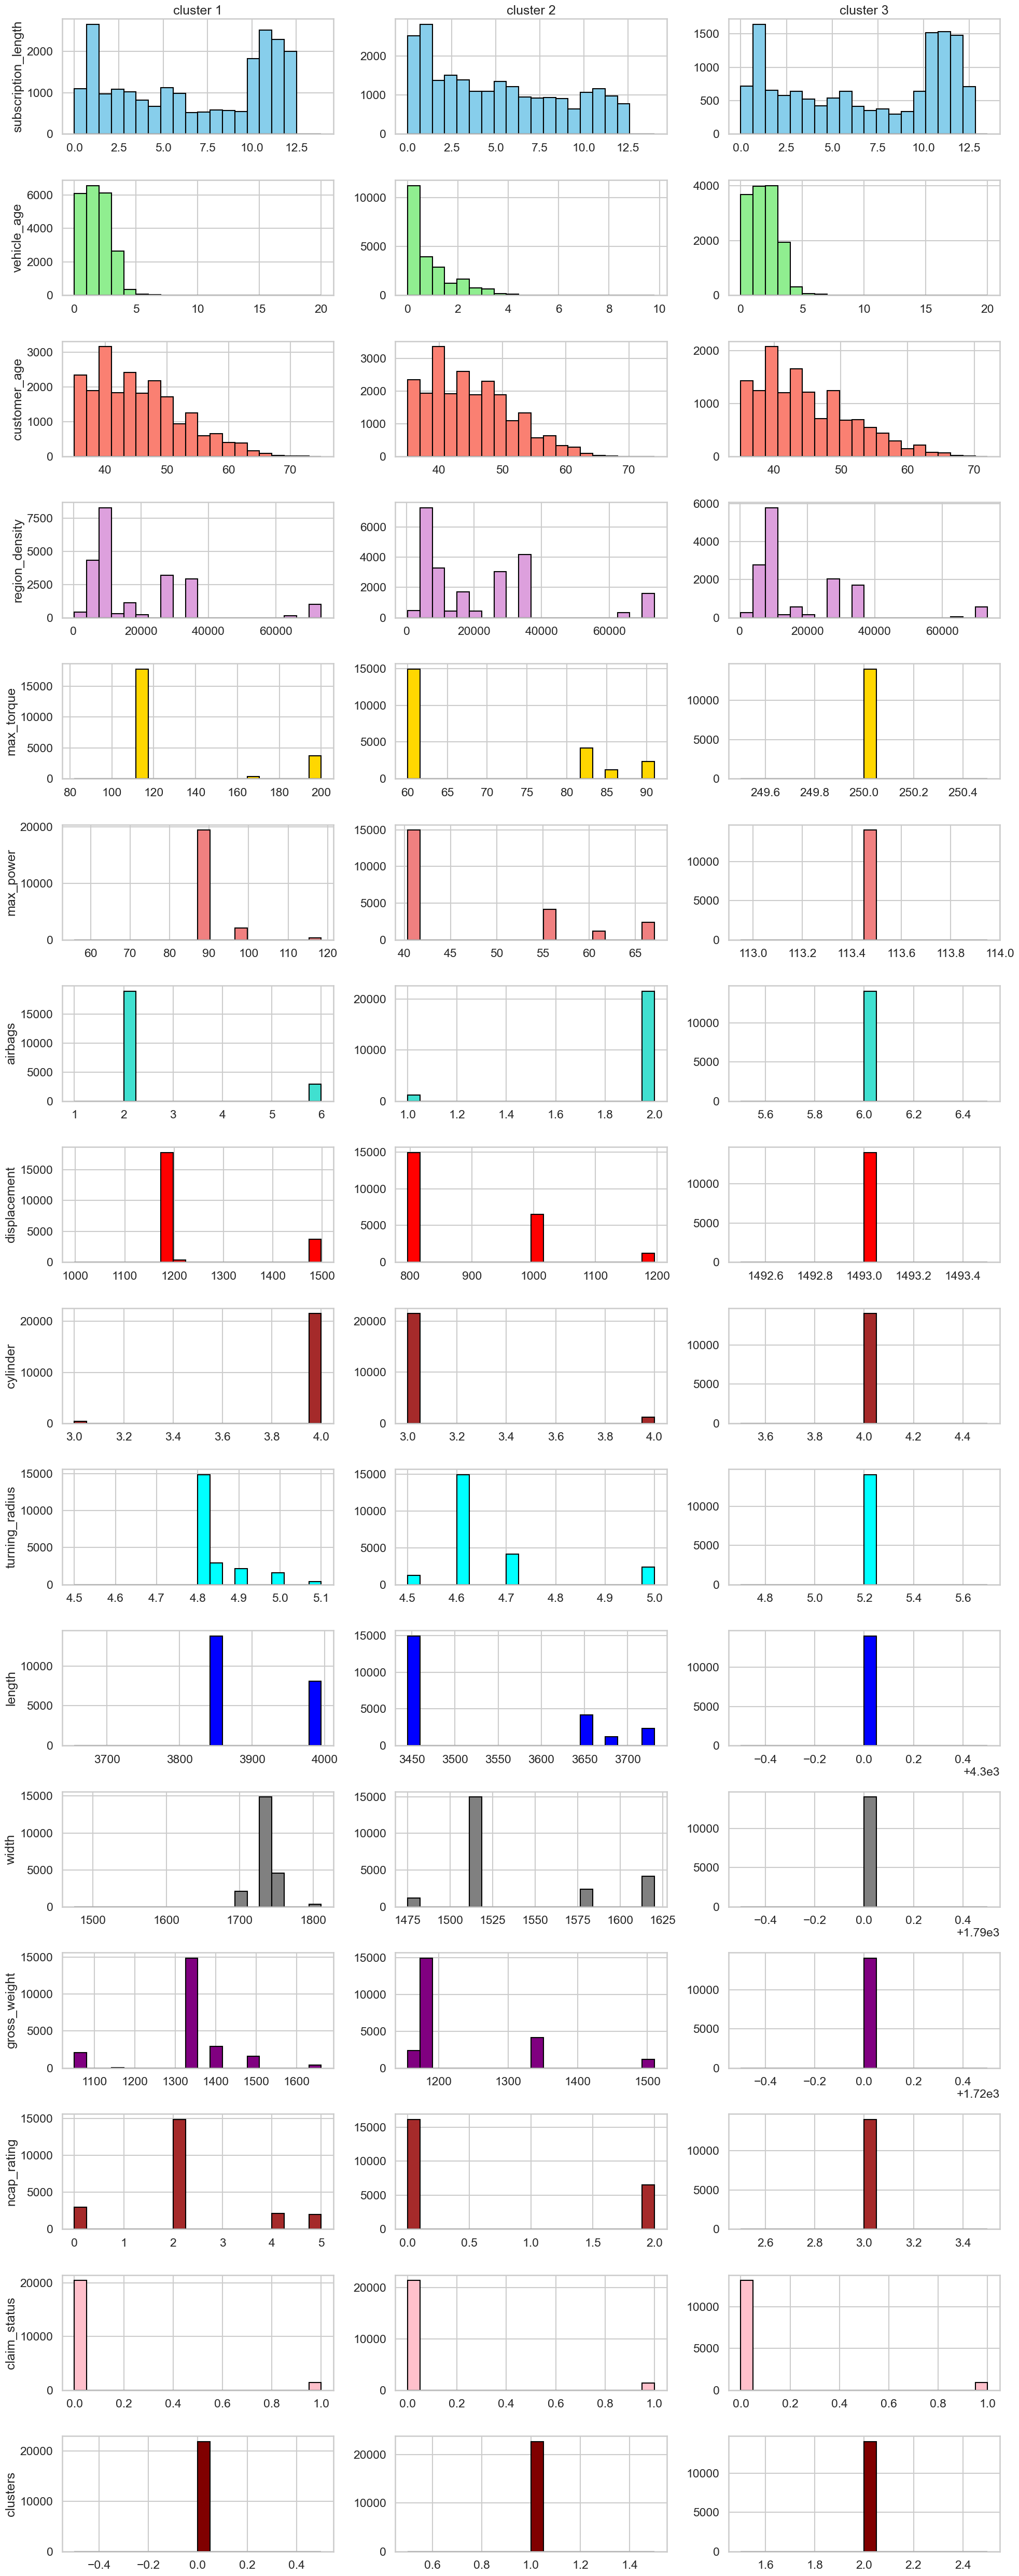

In [734]:
fig, axes = plt.subplots(16, 3, figsize=(20, 50))  # 4 lignes, 4 colonnes
axes = axes.flatten()  # aplatir pour boucle facile
colo = ['skyblue', 'lightgreen', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise','red','brown','cyan','blue','gray','purple','brown','pink','maroon']
colors=[c for c in colo for _ in range(3)]
bases=[x1,x2,x3]
for i in range(len(num_cols)):
        axes[3*i].hist(x1[num_cols[i]],bins=20,color=colors[3*i],edgecolor='black')
        axes[3*i+1].hist(x2[num_cols[i]],bins=20,color=colors[3*i+1],edgecolor='black')
        axes[3*i+2].hist(x3[num_cols[i]],bins=20,color=colors[3*i+2],edgecolor='black')
        if i==0:
            axes[3*i].set_title(f"cluster {1}")
            axes[3*i+1].set_title(f"cluster {2}")
            axes[3*i+2].set_title(f"cluster {3}")
        axes[3*i].set_ylabel(f"{num_cols[i]}")
plt.tight_layout()
plt.show()

In [735]:
fig, axes = plt.subplots(8, 3, figsize=(90, 60))  # 7 lignes, 4 colonnes
axes = axes.flatten()  # aplatir pour boucle facile
colo = ['skyblue', 'salmon', 'plum', 'gold', 'lightcoral', 'turquoise','green','skyblue']
colors=[c for c in colo for _ in range(3)]
for i, col in enumerate(nominales_cols):
    sns.countplot(x=col,data=x1, ax=axes[3*i], color=colors[3*i])
    sns.countplot(x=col,data=x2, ax=axes[3*i+1], color=colors[3*i+1])
    sns.countplot(x=col,data=x3, ax=axes[3*i+2], color=colors[3*i+2])
    if i==0:
        axes[3*i].set_title(f"cluster {1}")
        axes[3*i].tick_params(axis='x',rotation=90)#on fait une rotation si les noms sont trop long
        axes[3*i+1].set_title(f"cluster {2}")
        axes[3*i+1].tick_params(axis='x',rotation=90)#on fait une rotation si les noms sont trop long
        axes[3*i+2].set_title(f"cluster {3}")
        axes[3*i+2].tick_params(axis='x',rotation=90)#on fait une rotation si les noms sont trop long
    axes[3*i].set_ylabel(f"{nominales_cols[i]}")

plt.tight_layout()
plt.show()

<h2 style="color: cyan; text-align: center">classification d'un nouvel individu dans un des clusters</h2>

Nous avons déjà décris nos clusters, et les analyser. Nous allons maintenant déterminer, pour un nouvel individu, à quel groupe il appartient.

In [736]:
yes_no_cols=[col for col in df.columns if set(df[col].unique())<= {'Yes','No'}]
nominales_cols=[col for col in df.columns if df[col].dtype==object and col not in yes_no_cols]
nominales_cols.remove("policy_id")
colones=['claim_status','clusters']
num_cols_i=[col for col in df.columns if np.issubdtype(df[col].dtype,np.integer) and col not in colones]
num_cols_f=[col for col in df.columns if np.issubdtype(df[col].dtype,np.floating)]
num_cols=num_cols_i+num_cols_f

In [737]:
#entrainement
X=df[yes_no_cols+num_cols+nominales_cols]
# on commence par les encodages
#variables binaire
for col in yes_no_cols:
    X[col] = X[col].map({'Yes': 1, 'No': 0})
#variables nominales
X = pd.get_dummies(X, columns=nominales_cols, drop_first=True)#pour supprimer les valeurs de moindre importance pour ne pas elargir la base de données inutilement

# variables numérique
scaler = StandardScaler()
scaler.fit(X[num_cols])
X[num_cols] = scaler.transform(X[num_cols])
nouvelles_colonnes=X.columns
# Entraînement sur les données 
kmeans=KMeans(n_clusters=3,random_state=42)
kmeans.fit(X)

C:\Users\FTAB TECH\AppData\Local\Temp\ipykernel_3316\4093424998.py:6: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\FTAB TECH\AppData\Local\Temp\ipykernel_3316\4093424998.py:6: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\FTAB TECH\AppData\Local\Temp\ipykernel_3316\4093424998.py:6: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [738]:
import panel as pn
pn.extension()
Policy_ID=pn.widgets.TextInput(name="votre identifiant: ")
dictio={}
#pour les variables nominales
for val_nom in nominales_cols:
    dictio[val_nom]=pn.widgets.Select(name=f"entrez la valeur de vorte {val_nom}", options=sorted(df[val_nom].unique()),width=500)
#pour les variables numériques
for col in num_cols_f:
    min_val=float(df[col].min())
    max_val=float(df[col].max())
    dictio[col]=pn.widgets.FloatSlider(name=f"entrer la valeur de votre {col}",start=min_val,end=max_val,value=(min_val+max_val)/2,step=0.01,width=500)

for col in num_cols_i:
    if col=="customer_age":
        min_val2=16
        max_val2=95
    else:
        min_val2=int(df[col].min())
        max_val2=int(df[col].max())
    dictio[col]=pn.widgets.IntSlider(name=f"entrer la valeur de votre {col}",start=min_val2,end=max_val2,step=1,width=500)

#pour les variables binaires yes no
for col in yes_no_cols:
    dictio[col]=pn.widgets.Select(name=col, options=['Yes','No'],width=500)


submit=pn.widgets.Button(name="valider", button_type='primary',width=200)
output_choices=pn.pane.Markdown("")
output_filt_df=pn.pane.Markdown("")

def action(event):
    nouvel_individu={}
    txt="## choix sélectionnés: \n"
    filt_df=df.copy()
    
    for col,widget in dictio.items():
        val=widget.value
        txt += f"-**{col}** : '{val}'\n"
        #pour les variables nominales 
        if col in nominales_cols or col in yes_no_cols:
            filt_df=filt_df[filt_df[col]==str(val).lower()]
            
        #pour les valeurs numériques entières
        elif col in num_cols_i:
            filt_df=filt_df[filt_df[col]==val]
            
        #pour les valeurs numériques décimales
        elif col in num_cols_f:
            filt_df=filt_df[(filt_df[col]>=float(df[col].min())) & (filt_df[col]<=float(df[col].max()))]

    
    #récupérons les données du nouvel individu
    for col, widget in dictio.items():
        nouvel_individu[col]=widget.value
        
    #convetissont tout cela en data frame
        df_individu=pd.DataFrame([nouvel_individu])
    #déteminons le clusteur de cet individu
    # on commence par les encodages
    df_ind=df_individu[yes_no_cols+num_cols+nominales_cols]
    #variables binaire
    for col in yes_no_cols:
        df_ind[col] = df_ind[col].map({'Yes': 1, 'No': 0})
    #variables nominales
    df_ind = pd.get_dummies(df_ind, columns=nominales_cols, drop_first=True)#pour supprimer les valeurs de moindre importance pour ne pas elargir la base de données inutilement
    
    
    # Ajouter colonnes manquantes
    for col in X.columns:
        if col not in df_ind.columns:
            df_ind[col] = 0
    # Réordonner
    df_ind = df_ind[X.columns]
    # variables numérique
    df_ind[num_cols] = scaler.transform(df_ind[num_cols])
    


    nouvelles_colonnes=df_ind.columns
    
    #trouvons le cluster de l'individu
    cluster = kmeans.predict(df_ind[nouvelles_colonnes])[0]
    #les choix pour le nouvel individu
    txt="Les choix pour le nouvel individu:\n"
    for col, val in nouvel_individu.items():
        txt +="\n ** {col} **: '{val}\n"
    txt=f"\n Cluster prédit pour cet individu: Cluster {cluster+1}"
    output_choices.object=txt
    
submit.on_click(action)

interface=pn.Column(pn.pane.Markdown("variables nominales"),pn.WidgetBox(*[dictio[col] for col in nominales_cols]),
                    pn.pane.Markdown("variables binaires"),pn.WidgetBox(*[dictio[col] for col in yes_no_cols]),
                    pn.pane.Markdown("variables entières"),pn.WidgetBox(*[dictio[col] for col in num_cols_i]),
                    pn.pane.Markdown("variables décimales"),pn.WidgetBox(*[dictio[col] for col in num_cols_f]),
                    submit,pn.layout.Divider(),output_choices,pn.layout.Divider(),output_filt_df)
interface

BokehModel(combine_events=True, render_bundle={'docs_json': {'d95f4276-54e7-4d48-ad81-778511fcffcd': {'version…